# Complaint Intelligence for Retail Banks

**MCSBT · Introduction to AI and Machine Learning · Final Term Project**

Group: Yohannes Belay Woldeyes, Vidak Vukadinovic, Jorge Plaza de los Reyes Álvarez

This notebook turns one year of real US bank complaints (CFPB, 2025) into tools for a bank's complaints team:

| Stage | Question it answers | Course method |
|---|---|---|
| Clean | Which complaints are copy-paste campaigns? | Deduplication (Assignment 1),<br>sentence embeddings + FAISS (Session 7) |
| Route | Which team should handle this complaint? | **Word2Vec** (Session 5, Assignment 2, Midterm),<br>compared with an LLM (Session 6) |
| Prioritise | Which complaints will end in a payout? | Supervised prediction (Session 3) |
| Watch | Which problems are surging this week? | **LDA topic modeling** (Sessions 3 and 5) |
| Assist | What happened in similar past cases? | **RAG** with FAISS and Qwen3-4B<br>(Sessions 6 and 7, Assignment 3) |
| Prove it | Does each part work? | Held-out labels, RAGAs, LLM-as-judge<br>with a human spot-check (Session 11, Assignment 4) |

The three main AI methods are **Word2Vec**, **LDA topic modeling** and **RAG with an LLM**. Every stage is checked against data we did not create ourselves: the product and issue the consumer chose, and how the company actually closed the complaint.

## 1. Business case

**The problem.** Every complaint a bank receives through the CFPB has to be read, sent to the right product team and answered within 15 days. Today this is done by hand. Problems that hit many customers at once (an outage, a fee error, a scam wave) first show up as a sudden wave of complaints, and a team reading them one by one notices late.

**The AI Canvas** (Session 2, slide 10):

| Box | Our answer |
|---|---|
| Prediction | The right team for each complaint, the chance it ends in a payout,<br>its topic, and the most similar past cases |
| Judgment | Missing a payout case or a surge costs more than reading one<br>extra complaint, so we favour catching cases (recall) |
| Action | Route automatically, review high-risk complaints first,<br>alert managers when a topic surges, give agents a case brief |
| Outcome | Routing accuracy, payouts caught in the riskiest 20%,<br>surges detected, faithful case briefs |
| Input | Complaint text, product, issue, company, date |
| Training | 2025 CFPB complaints with their real product, issue and outcome |
| Feedback | Agents correct routes and briefs; each month's closed<br>complaints are added to the training data |

**Success targets, fixed before running any model:**

| Stage | Metric | Compared with | Target |
|---|---|---|---|
| Clean | Flagged copy pairs a person confirms (20-pair check) | – | at least 18 of 20 |
| Route | Accuracy on held-out complaints | Keyword rules | at least 80%,<br>and better than keyword rules |
| Prioritise | Payouts caught when reviewing the riskiest 20% | Random review (20%) | at least 40% (2× random) |
| Watch | Topic coherence (c_v) | Untuned LDA | at least 0.40,<br>and better than untuned |
| Watch | Surge alarm after the dated January 2025 events | – | an alarm within 7 days |
| Assist | Past cases with the same issue in the top 5 (precision@5) | Keyword search (BM25) | better than BM25 |
| Assist | RAGAs faithfulness of the case briefs | – | at least 0.80 |
| Fairness | Shortfall in payouts caught for Older American<br>and Servicemember complaints | Complaints without a tag | at most 5 percentage points |

## 2. Setup

The notebook is built for a Colab GPU runtime (T4). The OpenAI key is read from Colab Secrets (`OPENAI_API_KEY`), as in Assignments 3 and 4, and is only used for the LLM comparison, topic names and the evaluation judge (`gpt-4o-mini`, list price USD 0.15 per million input tokens and USD 0.60 per million output tokens).

Three switches control the run:

- `QUICK_RUN = True` uses 6,000 complaints for a fast test of the whole notebook.
- `RUN_OPENAI = False` skips every OpenAI call.
- `RUN_QWEN` is switched on automatically when a GPU is available.

Every chart is also saved as a PNG in `figures/` for the slides.

In [9]:
!pip install -q gensim sentence-transformers faiss-cpu rank-bm25
!pip install -q ragas==0.4.3 langchain-community==0.4.1 "huggingface-hub<2"

In [10]:
import os
import re
import json
import time
import random
import shutil
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, classification_report,
                             average_precision_score, roc_auc_score, normalized_mutual_info_score)

from gensim.models import Word2Vec, LdaModel, CoherenceModel
from gensim.models.phrases import Phrases
from gensim.corpora import Dictionary

import torch
import faiss
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 220)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

QUICK_RUN = False
RUN_OPENAI = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RUN_QWEN = DEVICE == "cuda"

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"Device: {DEVICE} | QUICK_RUN={QUICK_RUN} | RUN_OPENAI={RUN_OPENAI} | RUN_QWEN={RUN_QWEN}")

Device: cuda | QUICK_RUN=False | RUN_OPENAI=True | RUN_QWEN=True


In [11]:
JUDGE_MODEL = "gpt-4o-mini"
PRICE_PER_1M_TOKENS = {"input": 0.15, "output": 0.60}

client = None
if RUN_OPENAI:
    from openai import OpenAI
    try:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
    except Exception:
        if not os.environ.get("OPENAI_API_KEY"):
            from getpass import getpass
            os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")
    client = OpenAI()


def ask_openai(system, user, max_tokens=300, json_mode=False):
    extra = {"response_format": {"type": "json_object"}} if json_mode else {}
    for attempt in range(3):
        try:
            response = client.chat.completions.create(
                model=JUDGE_MODEL, temperature=0, max_completion_tokens=max_tokens,
                messages=[{"role": "system", "content": system}, {"role": "user", "content": user}], **extra)
            usage = response.usage
            return response.choices[0].message.content.strip(), usage.prompt_tokens, usage.completion_tokens
        except Exception as error:
            if attempt == 2:
                raise error
            time.sleep(5)


print("OpenAI model:", JUDGE_MODEL if client else "switched off")

OpenAI model: gpt-4o-mini


In [12]:
PRODUCTS = ["Checking or savings account", "Credit card", "Money transfer, virtual currency, or money service",
            "Mortgage", "Vehicle loan or lease"]
SHORT = dict(zip(PRODUCTS, ["Checking/savings", "Credit card", "Money transfer", "Mortgage", "Vehicle loan"]))
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PRODUCT_COLOR = dict(zip(PRODUCTS, SERIES))
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 11, "text.color": INK, "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "lines.linewidth": 2,
})


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()

## 3. Data: source and procurement

| | |
|---|---|
| Source | CFPB Consumer Complaint Database, official narratives archive<br>(US government open data, listed on Data.gov) |
| Link | [consumerfinance.gov narratives archive](https://www.consumerfinance.gov/foia-requests/foia-electronic-reading-room/cfpb-consumer-complaint-database-narratives-archive/) |
| Files | The six 2025 exports, January–February to November–December:<br>5.4 million complaints, 1.2 million with a written story |
| Privacy | The CFPB removes names, account numbers and dates before<br>publishing; they appear as XXXX |
| Why 2025 | The CFPB's product and issue categories did not change between<br>August 2023 and October 2026, so every label means the same thing |
| Scope | The five product lines a retail bank runs: checking/savings,<br>credit cards, money transfers, mortgages, vehicle loans |
| Size | 183,544 complaints in scope; a random sample of 60,000<br>(seed 42) keeps Colab fast |
| Build script | `prepare_dataset.py` reads the six zip files and writes<br>`cfpb_bank_complaints_2025.csv` |

| Column | Meaning |
|---|---|
| `complaint_id` | CFPB complaint number (can be looked up on consumerfinance.gov) |
| `date_received` | Date the CFPB received the complaint |
| `product`, `sub_product` | Product chosen by the consumer |
| `issue`, `sub_issue` | Problem chosen by the consumer |
| `narrative` | The consumer's own description |
| `company`, `state` | Company the complaint is about, consumer's state |
| `tags` | "Older American", "Servicemember" or empty |
| `company_response` | How the company closed it, for example "Closed with monetary relief" |
| `timely_response` | Whether the company answered on time |

Upload `cfpb_bank_complaints_2025.zip` to the Colab file panel before running the next cell.

In [13]:
DATA_PATH = "cfpb_bank_complaints_2025.zip"

df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
if QUICK_RUN:
    df = df.sample(6000, random_state=SEED)
df["date_received"] = pd.to_datetime(df["date_received"])
df = df.sort_values(["date_received", "complaint_id"]).reset_index(drop=True)
df["week"] = df["date_received"].dt.to_period("W").dt.start_time
df["payout"] = (df["company_response"] == "Closed with monetary relief").astype(int)
df["n_words"] = df["narrative"].str.split().str.len()
SCALE = len(df) / 60_000

first_day = df["date_received"].min().normalize()
last_day = df["date_received"].max().normalize()
first_monday = first_day + pd.Timedelta(days=(7 - first_day.weekday()) % 7)
last_full_monday = last_day - pd.Timedelta(days=(last_day.weekday() + 1) % 7) - pd.Timedelta(days=6)
WEEKS = pd.date_range(first_monday, last_full_monday, freq="W-MON")

print(f"{len(df):,} complaints about {df['company'].nunique():,} companies, "
      f"received {first_day:%d %b %Y} to {last_day:%d %b %Y} ({len(WEEKS)} full weeks)")
display(df[["complaint_id", "date_received", "product", "issue", "company", "company_response", "narrative"]].head(3))

60,000 complaints about 925 companies, received 01 Jan 2025 to 31 Dec 2025 (51 full weeks)


,complaint_id,date_received,product,issue,company,company_response,narrative
0,11334577,2025-01-01,Mortgage,Trouble during payment process,"CARRINGTON MORTGAGE SERVICES, LLC",Closed with explanation,On XX/XX/year> I called Carrington Mortgage to request removal of escrow payments from our monthly mortgage payment so that my husband and I could pay these ourselves. They told me to send a written request to a spec...
1,11334654,2025-01-01,Checking or savings account,Problem caused by your funds being low,WELLS FARGO & COMPANY,Closed with explanation,Thousands of dollars of overdraft fees. \n\nWells Fargo
2,11334680,2025-01-01,Checking or savings account,Problem caused by your funds being low,KEYCORP,Closed with explanation,"I deposited a check for {$80.00} on XX/XX/year> with Key Bank via their mobile app. The check cleared and was credited to my account. 4 days later, Key Bank hit me with a {$72.00} fee. They claimed that the check was..."


In [14]:
overview = (df.groupby("product")
              .agg(complaints=("complaint_id", "size"),
                   median_words=("n_words", "median"),
                   payout_rate=("payout", "mean"),
                   on_time=("timely_response", lambda s: (s == "Yes").mean()),
                   top_company=("company", lambda s: s.value_counts().index[0]))
              .reindex(PRODUCTS))
overview.insert(1, "share", overview["complaints"] / len(df))
display(overview.style.format({"complaints": "{:,}", "share": "{:.1%}", "median_words": "{:.0f}",
                               "payout_rate": "{:.1%}", "on_time": "{:.1%}"}))

,complaints,share,median_words,payout_rate,on_time,top_company
product,,,,,,
Checking or savings account,"16,768",27.9%,129,10.4%,99.2%,NAVY FEDERAL CREDIT UNION
Credit card,"13,578",22.6%,168,15.7%,99.5%,CAPITAL ONE FINANCIAL CORPORATION
"Money transfer, virtual currency, or money service","21,304",35.5%,102,2.0%,98.9%,"Block, Inc."
Mortgage,"4,537",7.6%,219,1.8%,98.3%,"Shellpoint Partners, LLC"
Vehicle loan or lease,"3,813",6.4%,184,2.5%,98.1%,"SANTANDER HOLDINGS USA, INC."


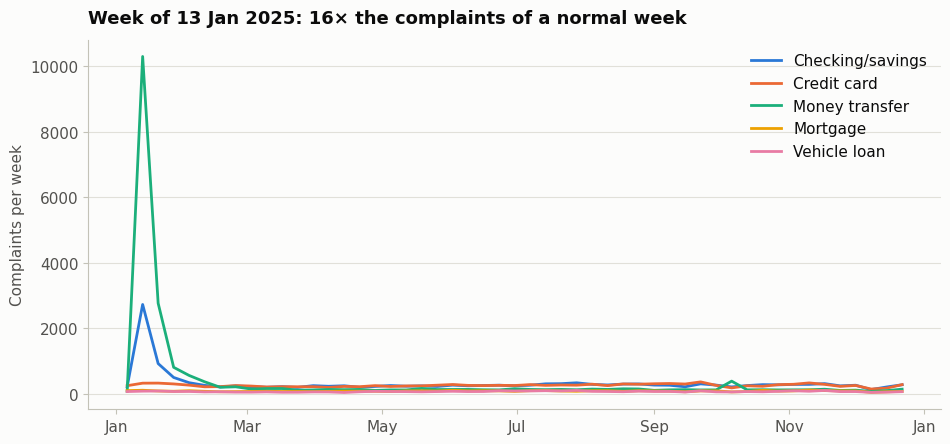

In [15]:
weekly = (df[df["week"].isin(WEEKS)].groupby(["week", "product"]).size()
            .unstack(fill_value=0).reindex(index=WEEKS, columns=PRODUCTS, fill_value=0))
weekly_total = weekly.sum(axis=1)
peak_week = weekly_total.idxmax()
peak_ratio = weekly_total.max() / weekly_total.median()

fig, ax = plt.subplots(figsize=(11, 4.8))
for product in PRODUCTS:
    ax.plot(weekly.index, weekly[product], color=PRODUCT_COLOR[product], label=SHORT[product])
ax.set_title(f"Week of {peak_week:%d %b %Y}: {peak_ratio:.0f}× the complaints of a normal week")
ax.set_ylabel("Complaints per week")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper right")
save_fig(fig, "fig01_weekly_complaints_by_product")

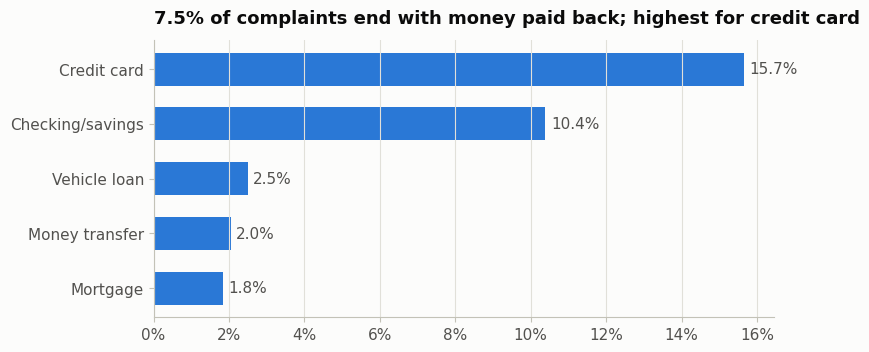

In [16]:
rates = overview["payout_rate"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh([SHORT[p] for p in rates.index], rates.values, color=SERIES[0], height=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in rates.values], padding=4, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title(f"{df['payout'].mean():.1%} of complaints end with money paid back; "
             f"highest for {SHORT[rates.index[-1]].lower()}")
save_fig(fig, "fig02_payout_rate_by_product")

## 4. Clean: copy-paste campaigns

Many complaints are not written from scratch. People share templates online and file the same text, and some people file one complaint against several companies. We need to find these copies for three reasons:

1. **Business:** a campaign can be answered in bulk with one reviewed response.
2. **Honest evaluation:** if one copy lands in the training set and another in the test set, the model has seen the answer and its score looks better than it really is. The low-scoring example project had no such check.
3. **Early warning:** a sudden campaign is itself a signal that something happened.

**Design choices.**

- Exact copies are found after cleaning the text, as in Assignment 1.
- Near copies (same template, different names or amounts) are found by meaning *and* by wording. Each complaint is turned into a sentence embedding (`all-mpnet-base-v2`, Session 7, Assignment 3), and FAISS finds its 10 closest complaints.
- A pair counts as a copy only if both checks agree: cosine similarity of at least 0.95, *and* at least half of their three-word sequences are shared.
- The same embeddings are reused later for the RAG assistant, so they are computed once.

In [17]:
def readable(text):
    text = re.sub(r"\{\$([\d,\.]+)\}", r"$\1", text)
    text = re.sub(r"X{2,}(?:/X{2,})*(?:/year>|/\d+)?", " ", text)
    text = re.sub(r"year>", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def clean_text(text):
    text = text.lower()
    text = re.sub(r"\$[\d,\.]+", " amount ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


df["text"] = df["narrative"].map(readable)
df["clean"] = df["text"].map(clean_text)
exact_copies = df["clean"].duplicated().sum()
print(f"Exact copies after cleaning: {exact_copies:,} of {len(df):,} ({exact_copies / len(df):.1%})")
print("\nExample before:", df.at[0, "narrative"][:200])
print("Example after: ", df.at[0, "clean"][:200])

Exact copies after cleaning: 10,905 of 60,000 (18.2%)

Example before: On XX/XX/year> I called Carrington Mortgage to request removal of escrow payments from our monthly mortgage payment so that my husband and I could pay these ourselves. They told me to send a written r
Example after:  on i called carrington mortgage to request removal of escrow payments from our monthly mortgage payment so that my husband and i could pay these ourselves they told me to send a written request to a s


In [18]:
EMBEDDING_MODEL = "sentence-transformers/all-mpnet-base-v2"
embedder = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)
embedder.max_seq_length = 256
if DEVICE == "cuda":
    embedder.half()

start = time.time()
emb = embedder.encode(df["text"].tolist(), batch_size=64, show_progress_bar=True,
                      convert_to_numpy=True, normalize_embeddings=True).astype("float32")
print(f"{emb.shape[0]:,} complaints embedded into {emb.shape[1]} numbers each in {time.time() - start:.0f} s")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/938 [00:00<?, ?it/s]

60,000 complaints embedded into 768 numbers each in 167 s


In [19]:
K_NEIGHBOURS = 10
SIM_THRESHOLD = 0.95
OVERLAP_THRESHOLD = 0.5

index_all = faiss.IndexFlatIP(emb.shape[1])
index_all.add(emb)
start = time.time()
sims, nbrs = index_all.search(emb, K_NEIGHBOURS)
print(f"Nearest neighbours for every complaint found in {time.time() - start:.0f} s")

cand = pd.DataFrame({"a": np.repeat(np.arange(len(df)), K_NEIGHBOURS), "b": nbrs.ravel(), "cosine": sims.ravel()})
cand = cand[(cand["a"] != cand["b"]) & (cand["b"] >= 0) & (cand["cosine"] >= 0.90)]
cand["lo"] = cand[["a", "b"]].min(axis=1)
cand["hi"] = cand[["a", "b"]].max(axis=1)
cand = cand.drop_duplicates(["lo", "hi"]).reset_index(drop=True)

shingle_cache = {}


def shingles(i, n=3):
    if i not in shingle_cache:
        words = df.at[i, "clean"].split()
        grams = [" ".join(words[j:j + n]) for j in range(max(len(words) - n + 1, 1))]
        shingle_cache[i] = {hash(g) for g in grams}
    return shingle_cache[i]


def word_overlap(i, j):
    a, b = shingles(i), shingles(j)
    return len(a & b) / len(a | b) if a and b else 0.0


cand["overlap"] = [word_overlap(i, j) for i, j in zip(cand["lo"], cand["hi"])]

sensitivity = pd.DataFrame([
    {"cosine at least": t,
     "candidate pairs": int((cand["cosine"] >= t).sum()),
     "also share half their wording": (cand.loc[cand["cosine"] >= t, "overlap"] >= OVERLAP_THRESHOLD).mean()}
    for t in [0.90, 0.93, 0.95, 0.97, 0.99]])
display(sensitivity.style.format({"candidate pairs": "{:,}", "also share half their wording": "{:.1%}"}))

Nearest neighbours for every complaint found in 16 s


,cosine at least,candidate pairs,also share half their wording
0,0.900000,"154,035",91.8%
1,0.930000,"150,529",93.4%
2,0.950000,"148,068",94.4%
3,0.970000,"144,009",96.0%
4,0.990000,"132,426",99.1%


The table shows how the two checks agree. The meaning check alone flags many pairs at 0.90 that do not share their wording (similar stories, different people). As the cosine threshold rises, almost every pair is confirmed by the wording check too. We keep 0.95 with the wording check, so a pair has to pass both.

In [20]:
pairs = cand[(cand["cosine"] >= SIM_THRESHOLD) & (cand["overlap"] >= OVERLAP_THRESHOLD)].copy()
parent = np.arange(len(df))


def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for a, b in zip(pairs["lo"], pairs["hi"]):
    root_a, root_b = find(a), find(b)
    if root_a != root_b:
        parent[max(root_a, root_b)] = min(root_a, root_b)

df["group"] = [find(i) for i in range(len(df))]
df["group_size"] = df.groupby("group")["group"].transform("size")
df["is_copy"] = df.index != df["group"]
pairs["group"] = df.loc[pairs["lo"], "group"].to_numpy()

COPY_SHARE = df["is_copy"].mean()
print(f"Complaints that copy an earlier one: {df['is_copy'].sum():,} ({COPY_SHARE:.1%})")
print(f"Groups of copies: {(df.groupby('group').size() > 1).sum():,}")
print(f"Unique complaints kept for modeling: {(~df['is_copy']).sum():,}")

Complaints that copy an earlier one: 16,392 (27.3%)
Groups of copies: 269
Unique complaints kept for modeling: 43,608


In [21]:
CAMPAIGN_MIN = max(5, round(20 * SCALE))
big = df[df["group_size"] >= CAMPAIGN_MIN].groupby("group")
campaigns = pd.DataFrame({
    "complaints": big.size(),
    "main company": big["company"].agg(lambda s: s.value_counts().index[0]),
    "product": big["product"].agg(lambda s: SHORT[s.value_counts().index[0]]),
    "first seen": big["date_received"].min().dt.strftime("%d %b %Y"),
    "busiest week": big["week"].agg(lambda s: s.value_counts().index[0]).dt.strftime("%d %b %Y"),
}).sort_values("complaints", ascending=False)
campaigns["opening words"] = [" ".join(df.at[g, "text"].split()[:18]) + " ..." for g in campaigns.index]
print(f"{len(campaigns)} campaigns with at least {CAMPAIGN_MIN} copies")
display(campaigns.head(10).reset_index(drop=True))

19 campaigns with at least 20 copies


,complaints,main company,product,first seen,busiest week,opening words
0,8729,"Block, Inc.",Money transfer,16 Jan 2025,13 Jan 2025,"I am filing a complaint against Cash App ( Block , Inc. ) due to inadequate customer service ..."
1,4030,"Early Warning Services, LLC",Money transfer,15 Jan 2025,13 Jan 2025,I am writing to formally express my concerns regarding Zelles handing disputes particularly in light of of the ...
2,1561,NAVY FEDERAL CREDIT UNION,Checking/savings,15 Jan 2025,13 Jan 2025,I am writing to file a complaint against Navy Federal Credit Union regarding multiple overdraft fees I have ...
3,395,CAPITAL ONE FINANCIAL CORPORATION,Checking/savings,17 Jan 2025,13 Jan 2025,l'am filing a complaint with the CFPB regarding Capital One 's failure to deposit my direct deposit from ...
4,175,"EQUIFAX, INC.",Credit card,14 Aug 2025,08 Sep 2025,My accounts was never late! I have had exceptional payment history with and all payments were placed on ...
5,134,NAVY FEDERAL CREDIT UNION,Checking/savings,18 Jan 2025,20 Jan 2025,am writing to formally file a complaint regarding multiple overdraft fees applied to my account. These fees were ...
6,130,CAPITAL ONE FINANCIAL CORPORATION,Checking/savings,17 Jan 2025,13 Jan 2025,"I am filing a complaint against Capital One regarding the deceptive practices related to their "" '' savings ..."
7,109,Experian Information Solutions Inc.,Credit card,28 Jul 2025,29 Sep 2025,My report shows late payment entries that I believe are inaccurate. According to 15 USC 1681e ( b ...
8,107,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Credit card,02 Jan 2025,06 Jan 2025,My information was heisted and this accounts are fraudulent and do not belong to me. I would like ...
9,90,Chime Financial Inc,Money transfer,18 Jan 2025,06 Oct 2025,"I am writing to formally express my concerns regarding chime handling of disputes, particularly in light of the ..."


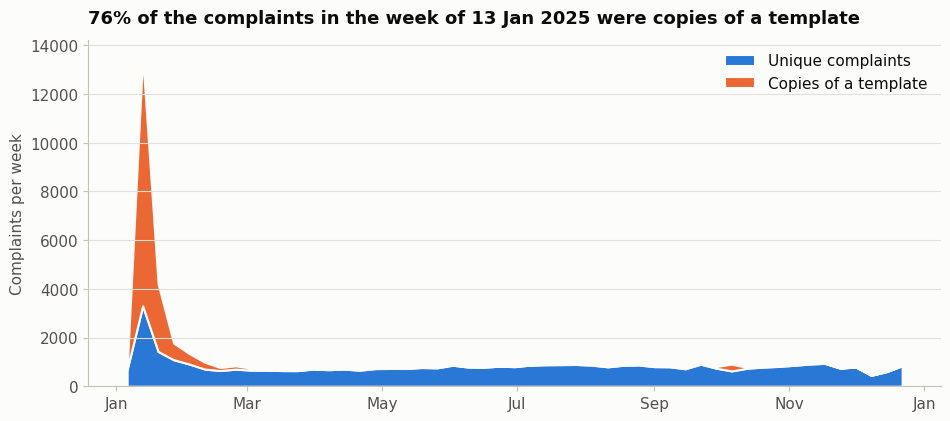

In [22]:
copies_weekly = (df[df["week"].isin(WEEKS)].groupby(["week", "is_copy"]).size()
                   .unstack(fill_value=0).reindex(index=WEEKS, columns=[False, True], fill_value=0))
peak_copy_share = copies_weekly.loc[peak_week, True] / copies_weekly.loc[peak_week].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(copies_weekly.index, copies_weekly[False], copies_weekly[True], colors=[SERIES[0], SERIES[1]],
             labels=["Unique complaints", "Copies of a template"], edgecolor=SURFACE, linewidth=1.5)
ax.set_title(f"{peak_copy_share:.0%} of the complaints in the week of {peak_week:%d %b %Y} were copies of a template")
ax.set_ylabel("Complaints per week")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper right")
save_fig(fig, "fig03_unique_vs_template_copies")

### Human check of the copy detector

Automatic agreement is not proof, so a person checks a sample. The cell below shows 20 flagged pairs, each from a *different* group. Random pairs would mostly come from the few huge campaigns and would be too easy to confirm.

Read each pair and count how many are really the same template or the same complaint filed twice. Then type that number into `HUMAN_CONFIRMED` and run the cell after the table again. The scorecard in section 10 uses it.

In [23]:
check_pairs = pairs.groupby("group").sample(1, random_state=SEED)
check_pairs = check_pairs.sample(min(20, len(check_pairs)), random_state=SEED)
human_check = pd.DataFrame({
    "complaint A": [" ".join(df.at[a, "text"].split()[:30]) for a in check_pairs["lo"]],
    "complaint B": [" ".join(df.at[b, "text"].split()[:30]) for b in check_pairs["hi"]],
    "cosine": check_pairs["cosine"].round(3).to_numpy(),
    "shared wording": check_pairs["overlap"].round(2).to_numpy(),
})
display(human_check)

,complaint A,complaint B,cosine,shared wording
0,I am writing to file a compliant against Navy Federal Credit Union regarding multiple overdraft fees I have incurred. Despite having sufficient funds whens transactions were authorized. I was charged,"I am writing to file a compliant against navy Federal Credit Union regarding multiple overdraft fees I have incurred. Despite having sufficient funds when transactions were authorized, I was charged",0.996,0.74
1,Account Number Ending In : Claim ID : Dispute Type : Debit - Unauthorized Transaction Date Error Reported : Claim Amount : $100.00 Account Number Ending In : Claim ID,Account Number Ending In : Claim ID : Dispute Type : Debit - Unauthorized Transaction Date Error Reported : Claim Amount : $100.00 Account Number Ending In : Claim ID,0.999,0.95
2,"I am seeking your help to investigate accounts from companies reporting late payments inaccurately. Upon reviewing my credit report, I discovered specific accounts marked with late payments, which is incorrect.","I am seeking your help to investigate accounts from companies reporting late payments inaccurately. Upon reviewing my credit report, I discovered specific accounts marked with late payments, which is incorrect.",1.000,1.00
3,Recently checking my credit report I notice that I had multiple collection and closed accounts. All of these accounts I have no knowledge of. They have been open and used,Recently checking my credit report I notice that I had multiple collection and closed accounts. All of these accounts I have no knowledge of. They have been open and used,0.974,0.92
4,"I state that the incorrect late payment entries on my accounts are in violation of 15 USC 1666. I have consistently paid on time, and any errors in this reporting","I state that the incorrect late payment entries on my accounts are in violation of 15 USC 1666. I have consistently paid on time, and any errors in this reporting",1.000,1.00
5,I fell victim to a phishing scam. I was called by someone impersonating a Wells Fargo Employee on . I was told that someone was trying to wire transfer money,I fell victim to a phishing scam. I was called by someone impersonating a Wells Fargo Employee on . I was told that someone was trying to wire transfer money,1.001,1.00
6,I recently reviewed my Early Warning Systems report and identified a fraudulent bank account that does not belong to me and that I do not recognize. This account is inaccurate,I recently reviewed my Early Warning Systems report and identified a fraudulent bank account that does not belong to me and that I do not recognize. This account is inaccurate,1.000,1.00
7,I am filing a complaint with the CFPB regarding Capital One 's failure to deposit my direct deposit from my employer and any other incoming deposits. Capital One has cited,I am filing a complaint with the CFPB regarding Capital One 's Failure to deposit my direct deposit from my employer and any other incoming deposits. Capital One has cited,1.000,0.93
8,"I have contacted the institution on numerous occassions asking them to provide me with proper consent that was was provided by me due to my information being brought, traded and","I have contacted the institution on numerous occassions asking them to provide me with proper consent that was was provided by me due to my information being brought, traded and",0.993,0.98
9,"I assert that the false late payment entries on my accounts violate the provisions of 15 USC 1666. My payments have always been made on time, and any errors in","I assert that the false late payment entries on my accounts violate the provisions of 15 USC 1666. My payments have always been made on time, and any errors in",1.001,1.00


In [24]:
HUMAN_CONFIRMED = 19
print("Pairs confirmed by a person:", HUMAN_CONFIRMED if HUMAN_CONFIRMED is not None else "not entered yet")

Pairs confirmed by a person: 19


## 5. Route: Word2Vec (main method 1)

**What it does.** It reads a complaint and sends it to one of the five product teams.

**Design choices.**

- **Word2Vec trained on the complaints themselves** (Session 5, Assignment 2, Midterm), so it learns bank language: "zelle" sits next to "scam" and "cash_app", "escrow" sits next to "mortgage". It is trained only on the training split.
- **Word pairs** such as `direct_deposit` and `credit_card` are learned with gensim `Phrases`. This is the "n-gram values" from the brief.
- **Skip-gram, 100 dimensions, 10 passes**, the settings that fixed underfitting in the midterm.
- A complaint becomes the average of its word vectors.
- **Template copies are removed**, and the remaining unique complaints are split 80/20 by product. The test set is never seen during training.

**What we compare.**

1. **Keyword rules:** a JSON keyword list per team, which is what a simple rules engine does today.
2. **Word2Vec + taxonomy:** the same keyword list, matched by meaning instead of exact words. It uses no labels at all (the brief's taxonomy idea).
3. **Word2Vec + logistic regression:** learns from the labelled training complaints. This is our proposed router.
4. **LLM zero-shot:** `gpt-4o-mini` reads the complaint and picks a team (Session 6). It runs on 300 test complaints because it costs money per call.

The ground truth is the product the consumer chose when filing, which none of the models can see.

In [25]:
STOP_WORDS = set(ENGLISH_STOP_WORDS)


def tokenize(text):
    return [w for w in text.split() if len(w) > 2 and w not in STOP_WORDS]


df["tokens"] = df["clean"].map(tokenize)
unique = df[~df["is_copy"]]
train_idx, test_idx = train_test_split(unique.index.to_numpy(), test_size=0.2,
                                       stratify=unique["product"], random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)

phrases = Phrases(df.loc[train_idx, "tokens"].tolist(), min_count=max(5, round(20 * SCALE)), threshold=10)
bigram = phrases.freeze()
df["tokens"] = [list(bigram[t]) for t in df["tokens"]]

learned_pairs = Counter(t for doc in df.loc[train_idx, "tokens"] for t in doc if "_" in t)
print(f"Train: {len(train_idx):,} unique complaints | Test: {len(test_idx):,} unique complaints")
print("Most frequent word pairs:", ", ".join(w for w, _ in learned_pairs.most_common(20)))

Train: 34,886 unique complaints | Test: 8,722 unique complaints
Most frequent word pairs: credit_card, wells_fargo, cash_app, customer_service, bank_america, checking_account, debit_card, credit_report, multiple_times, phone_number, business_days, navy_federal, american_express, filing_complaint, credit_reporting, late_fees, credit_score, consumer_financial, consumer_protection, did_receive


In [26]:
start = time.time()
w2v = Word2Vec(sentences=df.loc[train_idx, "tokens"].tolist(), vector_size=100, window=5, min_count=5,
               sg=1, epochs=10, workers=4, seed=SEED)
print(f"Vocabulary: {len(w2v.wv):,} words and word pairs, trained in {time.time() - start:.0f} s")

PROBES = ["zelle", "overdraft", "repossession", "chargeback", "escrow", "cash_app", "direct_deposit", "late_fee"]
probe_table = pd.DataFrame({w: [f"{s} ({score:.2f})" for s, score in w2v.wv.most_similar(w, topn=5)]
                            for w in PROBES if w in w2v.wv}, index=[f"#{i}" for i in range(1, 6)]).T
display(probe_table)

Vocabulary: 13,957 words and word pairs, trained in 68 s


,#1,#2,#3,#4,#5
zelle,using_zelle (0.75),zelles (0.70),wrong_person (0.70),zell (0.66),remitly (0.61)
overdraft,overdraft_fee (0.77),overdraft_fees (0.77),charged_overdraft (0.75),overdrafts (0.75),overdraft_protection (0.72)
repossession,repossession_vehicle (0.79),repossessed_vehicle (0.78),repo (0.77),repossessed (0.76),vehicle_repossessed (0.75)
chargeback,merchant (0.69),dispute (0.69),card_issuer (0.67),service_rendered (0.66),sided (0.64)
escrow,taxes_insurance (0.77),property_taxes (0.76),shortage (0.75),hazard_insurance (0.75),escrow_analysis (0.74)
cash_app,cashapp (0.89),chime (0.70),cash_apps (0.68),square (0.64),cashapps (0.64)
direct_deposit,direct_deposits (0.84),employer (0.77),paycheck (0.77),paychecks (0.76),payroll (0.74)
late_fee,late_fees (0.79),assessed (0.73),waived (0.70),trailing (0.70),fee_waived (0.69)


In [27]:
def doc_vector(tokens):
    vectors = [w2v.wv[t] for t in tokens if t in w2v.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(w2v.vector_size, dtype="float32")


X_w2v = np.vstack([doc_vector(t) for t in df["tokens"]]).astype("float32")
y_product = df["product"].to_numpy()
y_test = y_product[test_idx]

TAXONOMY = {
    "Checking or savings account": ["checking", "savings", "overdraft", "debit", "deposit", "deposits",
                                    "atm", "branch", "withdrawal", "nsf"],
    "Credit card": ["credit_card", "card", "cards", "statement", "apr", "limit", "annual", "rewards",
                    "purchase", "merchant"],
    "Money transfer, virtual currency, or money service": ["zelle", "cash_app", "cashapp", "paypal", "venmo",
                                                          "wire", "transfer", "crypto", "bitcoin", "coinbase"],
    "Mortgage": ["mortgage", "escrow", "modification", "foreclosure", "refinance", "servicer", "home",
                 "property", "heloc", "appraisal"],
    "Vehicle loan or lease": ["car", "vehicle", "auto", "repossession", "repossessed", "lease", "dealership",
                              "dealer", "title", "repo"],
}
with open("taxonomy.json", "w") as f:
    json.dump(TAXONOMY, f, indent=2)

MOST_COMMON = pd.Series(y_product[train_idx]).mode()[0]


def keyword_route(tokens):
    bag = Counter(tokens + [part for t in tokens if "_" in t for part in t.split("_")])
    counts = {p: sum(bag[k] for k in words) for p, words in TAXONOMY.items()}
    best = max(counts, key=counts.get)
    return best if counts[best] > 0 else MOST_COMMON


centroids = np.vstack([np.mean([w2v.wv[k] for k in words if k in w2v.wv], axis=0) for words in TAXONOMY.values()])
centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
TEAM_NAMES = np.array(list(TAXONOMY))


def taxonomy_route(X):
    X_norm = X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-9, None)
    return TEAM_NAMES[np.argmax(X_norm @ centroids.T, axis=1)]


router = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
router.fit(X_w2v[train_idx], y_product[train_idx])

timings = {}
start = time.time()
pred_kw = np.array([keyword_route(t) for t in df.loc[test_idx, "tokens"]])
timings["Keyword rules (today)"] = (time.time() - start) / len(test_idx) * 1000
start = time.time()
pred_tax = taxonomy_route(X_w2v[test_idx])
timings["Word2Vec + taxonomy (no labels)"] = (time.time() - start) / len(test_idx) * 1000
start = time.time()
pred_lr = router.predict(X_w2v[test_idx])
timings["Word2Vec + logistic regression"] = (time.time() - start) / len(test_idx) * 1000
route_pred = dict(zip(test_idx, pred_lr))
print("Routing models trained and evaluated on", f"{len(test_idx):,}", "test complaints")

Routing models trained and evaluated on 8,722 test complaints


In [28]:
N_LLM = 60 if QUICK_RUN else 300
llm_rows = pd.Series(test_idx).sample(N_LLM, random_state=SEED).to_numpy()
ROUTER_SYSTEM = ("You route bank customer complaints to the team that owns the product. "
                 "Reply with exactly one of these team names and nothing else:\n" + "\n".join(PRODUCTS))
TEAM_KEYS = {"checking": PRODUCTS[0], "credit card": PRODUCTS[1], "money transfer": PRODUCTS[2],
             "mortgage": PRODUCTS[3], "vehicle": PRODUCTS[4]}


def parse_team(reply):
    reply = reply.lower()
    for key, product in TEAM_KEYS.items():
        if key in reply:
            return product
    return "Unparsed"


pred_llm = None
if RUN_OPENAI:
    pred_llm, tokens_in, tokens_out = [], 0, 0
    start = time.time()
    for row in llm_rows:
        reply, t_in, t_out = ask_openai(ROUTER_SYSTEM, " ".join(df.at[row, "text"].split()[:250]), max_tokens=20)
        pred_llm.append(parse_team(reply))
        tokens_in += t_in
        tokens_out += t_out
    pred_llm = np.array(pred_llm)
    timings["LLM zero-shot (gpt-4o-mini)"] = (time.time() - start) / N_LLM * 1000
    llm_cost_per_1000 = ((tokens_in * PRICE_PER_1M_TOKENS["input"] + tokens_out * PRICE_PER_1M_TOKENS["output"])
                         / 1e6 / N_LLM * 1000)
    print(f"LLM routed {N_LLM} complaints, {np.mean(pred_llm == 'Unparsed'):.1%} unparsed replies, "
          f"USD {llm_cost_per_1000:.3f} per 1,000 complaints")
else:
    print("LLM comparison skipped (RUN_OPENAI = False)")

LLM routed 300 complaints, 0.7% unparsed replies, USD 0.038 per 1,000 complaints


In [29]:
test_pos = {row: k for k, row in enumerate(test_idx)}
sub = np.array([test_pos[row] for row in llm_rows])
y_sub = y_test[sub]

routing_preds = {
    "Keyword rules (today)": pred_kw,
    "Word2Vec + taxonomy (no labels)": pred_tax,
    "Word2Vec + logistic regression": pred_lr,
}
routing_rows = []
for name, pred in routing_preds.items():
    routing_rows.append({"model": name,
                         "accuracy (all test)": accuracy_score(y_test, pred),
                         "macro-F1 (all test)": f1_score(y_test, pred, average="macro"),
                         f"accuracy ({N_LLM} sample)": accuracy_score(y_sub, pred[sub]),
                         "USD per 1,000": 0.0,
                         "ms per complaint": timings[name]})
if pred_llm is not None:
    routing_rows.append({"model": "LLM zero-shot (gpt-4o-mini)",
                         "accuracy (all test)": np.nan, "macro-F1 (all test)": np.nan,
                         f"accuracy ({N_LLM} sample)": accuracy_score(y_sub, pred_llm),
                         "USD per 1,000": llm_cost_per_1000,
                         "ms per complaint": timings["LLM zero-shot (gpt-4o-mini)"]})
routing_results = pd.DataFrame(routing_rows).set_index("model")
formats = {c: "{:.1%}" for c in routing_results.columns if "accuracy" in c or "F1" in c}
formats.update({"USD per 1,000": "{:.3f}", "ms per complaint": "{:.2f}"})
display(routing_results.style.format(formats, na_rep="–"))

ACC_KW = routing_results.loc["Keyword rules (today)", "accuracy (all test)"]
ACC_ROUTER = routing_results.loc["Word2Vec + logistic regression", "accuracy (all test)"]
F1_ROUTER = routing_results.loc["Word2Vec + logistic regression", "macro-F1 (all test)"]
report = pd.DataFrame(classification_report(y_test, pred_lr, output_dict=True)).T.loc[PRODUCTS]
report.index = [SHORT[p] for p in report.index]
display(report[["precision", "recall", "f1-score", "support"]].style.format(
    {"precision": "{:.2f}", "recall": "{:.2f}", "f1-score": "{:.2f}", "support": "{:,.0f}"}))

,accuracy (all test),macro-F1 (all test),accuracy (300 sample),"USD per 1,000",ms per complaint
model,,,,,
Keyword rules (today),70.6%,73.9%,71.0%,0.000,0.03
Word2Vec + taxonomy (no labels),68.7%,66.8%,66.0%,0.000,0.00
Word2Vec + logistic regression,80.9%,82.3%,80.7%,0.000,0.00
LLM zero-shot (gpt-4o-mini),–,–,78.0%,0.038,721.38


,precision,recall,f1-score,support
Checking/savings,0.80,0.75,0.78,"2,890"
Credit card,0.87,0.82,0.84,"2,525"
Money transfer,0.72,0.78,0.75,"1,642"
Mortgage,0.90,0.93,0.92,906
Vehicle loan,0.77,0.91,0.83,759


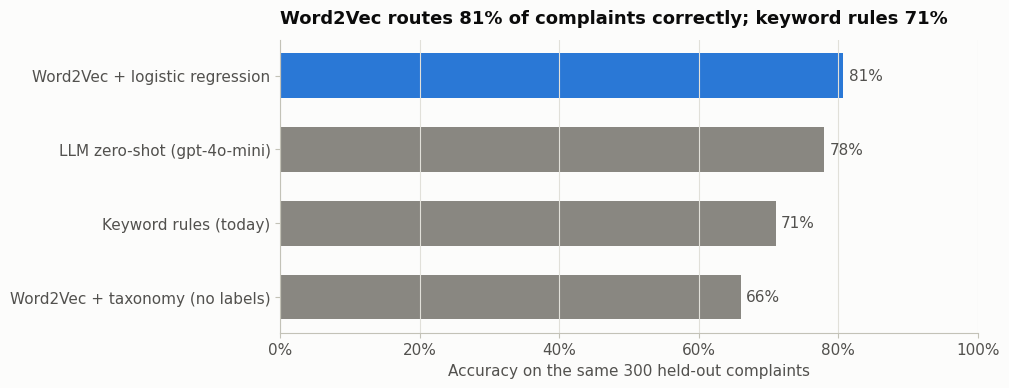

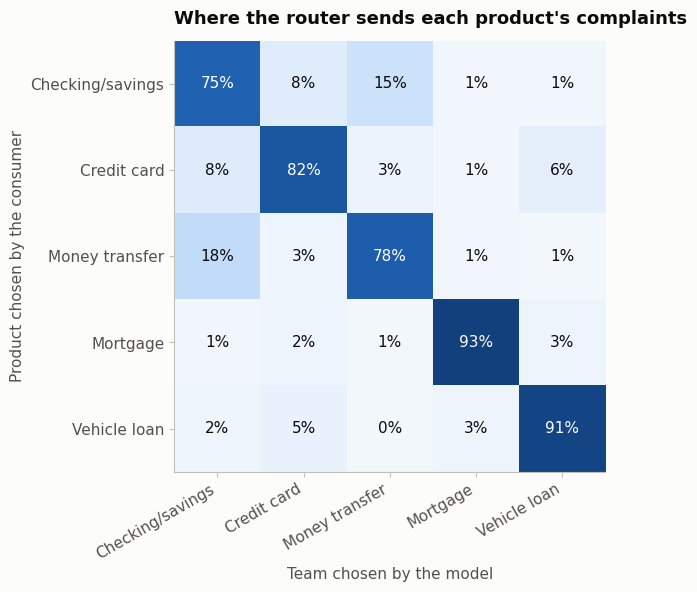

In [30]:
sample_acc = routing_results[f"accuracy ({N_LLM} sample)"].sort_values()
colors = [SERIES[0] if name == "Word2Vec + logistic regression" else MUTED for name in sample_acc.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(sample_acc.index, sample_acc.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in sample_acc.values], padding=4, color=INK_2)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title(f"Word2Vec routes {sample_acc['Word2Vec + logistic regression']:.0%} of complaints correctly; "
             f"keyword rules {sample_acc['Keyword rules (today)']:.0%}")
ax.set_xlabel(f"Accuracy on the same {N_LLM} held-out complaints")
save_fig(fig, "fig04_routing_accuracy")

cm = confusion_matrix(y_test, pred_lr, labels=PRODUCTS, normalize="true")
fig, ax = plt.subplots(figsize=(7, 5.6))
ax.imshow(cm, cmap=BLUES, vmin=0, vmax=1)
ax.grid(False)
labels = [SHORT[p] for p in PRODUCTS]
ax.set_xticks(range(5), labels, rotation=30, ha="right")
ax.set_yticks(range(5), labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else INK)
ax.set_xlabel("Team chosen by the model")
ax.set_ylabel("Product chosen by the consumer")
ax.set_title("Where the router sends each product's complaints")
save_fig(fig, "fig05_routing_confusion_matrix")

## 6. Prioritise: which complaints will end in a payout?

**What it does.** It gives every new complaint a payout risk, so the team reviews the riskiest ones first.

**Ground truth.** How the company really closed the complaint: "Closed with monetary relief" or not. Only about 1 complaint in 13 ends in a payout, so accuracy would be misleading: a model that always says "no payout" would be 93% accurate. We use these measures instead:

- **Payouts caught in the riskiest 20%:** if staff review the 20% highest-risk complaints, what share of all payouts do they catch? Random review catches 20%.
- **PR-AUC** (average precision) and **ROC-AUC**.

**Design choices.**

- Logistic regression on the Word2Vec complaint vector plus the product and the length of the story.
- Balanced class weights, because payouts are rare. The low-scoring example dealt with imbalance by throwing data away (down-sampling) and then reported accuracy.
- Compared with a product-only model, to show what the text adds beyond the product.

In [31]:
product_onehot = pd.get_dummies(df["product"]).reindex(columns=PRODUCTS, fill_value=0).to_numpy(dtype=float)
X_pay = np.hstack([X_w2v, product_onehot, np.log1p(df["n_words"].to_numpy(dtype=float))[:, None]])
y_pay = df["payout"].to_numpy()
y_pay_test = y_pay[test_idx]

product_model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(product_onehot[train_idx], y_pay[train_idx])
payout_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5))
payout_model.fit(X_pay[train_idx], y_pay[train_idx])

rng = np.random.default_rng(SEED)
jitter = rng.random(len(test_idx)) * 1e-9
payout_scores = {
    "Random review": rng.random(len(test_idx)),
    "Product only": product_model.predict_proba(product_onehot[test_idx])[:, 1] + jitter,
    "Word2Vec text + product": payout_model.predict_proba(X_pay[test_idx])[:, 1],
}


def caught_at(y, scores, share=0.2):
    top = np.argsort(-scores, kind="stable")[:int(round(len(scores) * share))]
    return y[top].sum() / y.sum()


payout_results = pd.DataFrame([{
    "model": name,
    "PR-AUC": average_precision_score(y_pay_test, s),
    "ROC-AUC": roc_auc_score(y_pay_test, s),
    "payouts caught in riskiest 20%": caught_at(y_pay_test, s),
    "payout rate in riskiest 20%": y_pay_test[np.argsort(-s, kind="stable")[:int(round(len(s) * 0.2))]].mean(),
} for name, s in payout_scores.items()]).set_index("model")
print(f"Payout rate in the test set: {y_pay_test.mean():.1%} ({y_pay_test.sum():,} payouts)")
display(payout_results.style.format("{:.3f}", subset=["PR-AUC", "ROC-AUC"])
                      .format("{:.1%}", subset=["payouts caught in riskiest 20%", "payout rate in riskiest 20%"]))
CAUGHT_20 = payout_results.loc["Word2Vec text + product", "payouts caught in riskiest 20%"]

Payout rate in the test set: 10.1% (885 payouts)


,PR-AUC,ROC-AUC,payouts caught in riskiest 20%,payout rate in riskiest 20%
model,,,,
Random review,0.102,0.497,20.7%,10.5%
Product only,0.143,0.652,28.8%,14.6%
Word2Vec text + product,0.270,0.788,52.0%,26.4%


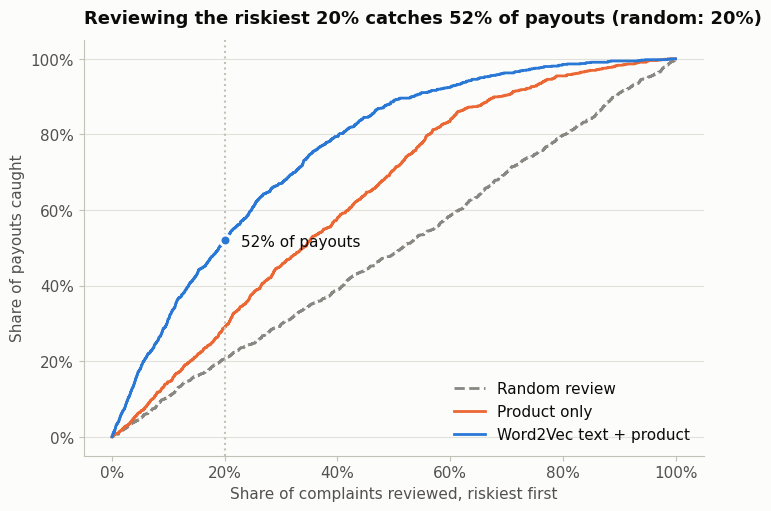

In [32]:
fig, ax = plt.subplots(figsize=(8, 5.4))
styles = {"Word2Vec text + product": (SERIES[0], "-"), "Product only": (SERIES[1], "-"), "Random review": (MUTED, "--")}
for name, s in payout_scores.items():
    order = np.argsort(-s, kind="stable")
    caught = np.concatenate([[0], np.cumsum(y_pay_test[order]) / y_pay_test.sum()])
    reviewed = np.linspace(0, 1, len(caught))
    color, line = styles[name]
    ax.plot(reviewed, caught, color=color, linestyle=line, label=name)
ax.axvline(0.2, color=AXIS, linestyle=":", linewidth=1.5)
ax.scatter([0.2], [CAUGHT_20], s=60, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.annotate(f"{CAUGHT_20:.0%} of payouts", (0.2, CAUGHT_20), xytext=(12, -4), textcoords="offset points", color=INK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Share of complaints reviewed, riskiest first")
ax.set_ylabel("Share of payouts caught")
ax.set_title(f"Reviewing the riskiest 20% catches {CAUGHT_20:.0%} of payouts (random: 20%)")
ax.legend(loc="lower right")
save_fig(fig, "fig06_payout_gains_curve")

### Fairness check

The CFPB tags complaints from older Americans and from servicemembers. These groups should not have their payouts missed more often than everyone else. This fairness measure is called "equal opportunity" (fairness is covered in Session 12). For each group we measure the share of its real payouts that land in the riskiest 20%. We count only a *shortfall* against untagged complaints, because a group that is caught more often is not harmed. The margin of error shows how much the number could move by chance, since the tagged groups are small.

In [33]:
risk = payout_scores["Word2Vec text + product"]
threshold = np.sort(risk)[::-1][int(round(len(risk) * 0.2)) - 1]
flagged = risk >= threshold
test_tags = df.loc[test_idx, "tags"].to_numpy()
groups = {
    "No tag": test_tags == "",
    "Older American": np.char.find(test_tags.astype(str), "Older American") >= 0,
    "Servicemember": np.char.find(test_tags.astype(str), "Servicemember") >= 0,
}
fairness = pd.DataFrame([{
    "group": name,
    "complaints": int(mask.sum()),
    "payouts": int(y_pay_test[mask].sum()),
    "share flagged as high risk": flagged[mask].mean(),
    "payouts caught": flagged[mask & (y_pay_test == 1)].mean() if y_pay_test[mask].sum() else np.nan,
} for name, mask in groups.items()]).set_index("group")
fairness["margin of error (95%)"] = 1.96 * np.sqrt(fairness["payouts caught"] * (1 - fairness["payouts caught"])
                                                   / fairness["payouts"].clip(lower=1))
fairness["shortfall vs no tag"] = (fairness.loc["No tag", "payouts caught"] - fairness["payouts caught"]).clip(lower=0)
FAIRNESS_GAP = fairness["shortfall vs no tag"].max()
display(fairness.style.format({"complaints": "{:,}", "payouts": "{:,}", "share flagged as high risk": "{:.1%}",
                               "payouts caught": "{:.1%}", "margin of error (95%)": "± {:.1%}",
                               "shortfall vs no tag": "{:.1%}"}, na_rep="–"))
print(f"Largest shortfall in payouts caught for a tagged group: {FAIRNESS_GAP * 100:.1f} percentage points")

,complaints,payouts,share flagged as high risk,payouts caught,margin of error (95%),shortfall vs no tag
group,,,,,,
No tag,"7,123",729,19.6%,51.3%,± 3.6%,0.0%
Older American,708,78,29.0%,66.7%,± 10.5%,0.0%
Servicemember,"1,071",96,17.6%,49.0%,± 10.0%,2.3%


Largest shortfall in payouts caught for a tagged group: 2.3 percentage points


## 7. Watch: LDA topic modeling (main method 2)

**What it does.** It finds the topics customers complain about and counts them week by week. When a topic jumps to 3× its normal weekly volume, managers get an alarm.

**Design choices (the tuning the brief asks for).**

- **N-grams and number of topics:** single words, and single words plus learned word pairs, each tried with 6 to 20 topics. The most coherent combination wins (topic coherence c_v: the top words of a topic tend to appear together, so people can read it).
- **Minimum and maximum document frequency:** words in fewer than 10 complaints are dropped, and the share of complaints above which a word is too common to help (0.2, 0.4, 0.7) is tuned for the winning combination.
- **Untuned baseline:** only standard English stop words removed, no frequency filtering, 10 topics. This is the low-scoring example's setup, whose topics were full of "like", "get" and "im".
- Bank and company names (Wells Fargo, Navy Federal, ...) and words that only fill templates are removed, so the topics describe *problems*, not companies. A surge at one bank still shows up, because its complaints share one problem.
- Trained on unique complaints, so a campaign does not take over a topic. Then applied to *all* complaints, because the volume of copies is part of the alarm signal.

**Evaluation.**

1. Coherence compared with the untuned baseline. Coherence alone can be fooled, because filler words that appear everywhere also appear together, so we also measure:
2. Agreement with the CFPB's own issue labels (normalized mutual information): do the topics separate real problems? Compared with the untuned model and with random topics.
3. Whether the alarm fires after real, dated events in January 2025.

In [34]:
LDA_STOP = {
    "amount", "told", "said", "say", "says", "called", "call", "calls", "calling", "time", "times", "day", "days",
    "would", "could", "also", "get", "got", "getting", "back", "even", "one", "two", "still", "never", "want",
    "wanted", "made", "make", "know", "like", "since", "asked", "ask", "asking", "received", "receive", "help",
    "helped", "contacted", "contact", "phone", "number", "please", "company", "customer", "service", "just",
    "going", "went", "did", "does", "way", "need", "needed", "dont", "didnt", "able", "use", "used", "new",
    "month", "months", "year", "years", "week", "weeks", "today", "however", "multiple", "without", "another",
    "regarding", "request", "requested", "stated", "state", "let", "take", "took", "tried", "try", "trying",
    "sent", "send", "provided", "provide", "informed", "issue", "issues", "problem", "complaint", "complaints",
    "file", "filed", "filing", "cfpb", "bureau", "consumer", "financial", "protection", "letter", "email",
    "information", "thank", "thanks", "sincerely", "currently", "regards", "understand", "despite", "review",
    "consumers", "documentation", "required", "accordance", "pursuant", "formally", "writing", "concerns",
    "wells", "fargo", "wells_fargo", "bank_america", "america", "chase", "citi", "citibank", "capital",
    "capital_one", "navy", "federal", "navy_federal", "sofi", "synchrony", "discover", "american_express",
    "amex", "barclays", "pnc", "truist", "ally", "santander", "goldman", "sachs", "chime", "usaa", "citizens",
    "huntington", "regions", "comerica", "flagstar", "shellpoint", "rocket", "carvana", "westlake",
}


def lda_tokens(tokens):
    return [t for t in tokens if t not in LDA_STOP and not any(part in LDA_STOP for part in t.split("_"))]


def unigram_tokens(i):
    return [t for t in tokenize(df.at[i, "clean"]) if t not in LDA_STOP]


def build_corpus(texts, no_below, no_above, keep_n=20000):
    dictionary = Dictionary(texts)
    dictionary.filter_extremes(no_below=no_below, no_above=no_above, keep_n=keep_n)
    return dictionary, [dictionary.doc2bow(t) for t in texts]


def fit_lda(dictionary, corpus, k, passes=4):
    return LdaModel(corpus=corpus, id2word=dictionary, num_topics=k, passes=passes, chunksize=2000,
                    alpha="auto", eta="auto", random_state=SEED, eval_every=None)


def coherence(model, texts, dictionary):
    return CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence="c_v",
                          processes=1).get_coherence()


df["lda_tokens"] = df["tokens"].map(lda_tokens)
unique_ids = np.sort(unique.index.to_numpy())
TUNE_N = min(8000, len(unique_ids))
tune_ids = np.random.default_rng(SEED).choice(unique_ids, TUNE_N, replace=False)
tune_pairs = [df.at[i, "lda_tokens"] for i in tune_ids]
tune_single = [unigram_tokens(i) for i in tune_ids]
tune_raw = [tokenize(df.at[i, "clean"]) for i in tune_ids]
NO_BELOW = 10
print(f"Tuning on {TUNE_N:,} unique complaints")

Tuning on 8,000 unique complaints


Single words       k= 6: c_v = 0.495 (16 s)
Single words       k= 8: c_v = 0.509 (19 s)
Single words       k=10: c_v = 0.485 (18 s)
Single words       k=12: c_v = 0.510 (18 s)
Single words       k=15: c_v = 0.479 (19 s)
Single words       k=20: c_v = 0.504 (22 s)
Words + word pairs k= 6: c_v = 0.459 (15 s)
Words + word pairs k= 8: c_v = 0.433 (18 s)
Words + word pairs k=10: c_v = 0.439 (16 s)
Words + word pairs k=12: c_v = 0.440 (16 s)
Words + word pairs k=15: c_v = 0.456 (18 s)
Words + word pairs k=20: c_v = 0.453 (18 s)


,setting,coherence,agreement with CFPB issues (NMI)
0,"Single words, 12 topics, max share 0.2",0.478,0.195
1,"Single words, 12 topics, max share 0.4",0.510,0.233
2,"Single words, 12 topics, max share 0.7",0.509,0.253
3,"Untuned: standard stop words only, no filtering, 10 topics",0.468,0.195


Chosen: Single words, 12 topics, max share 0.4 (c_v 0.510, untuned 0.468)

Top words of the untuned topics:
  0: cash, app, zelle, chase, express, account, bonus, service, american, customer
  1: account, bank, access, capital, funds, accounts, america, deposit, direct, financial
  2: application, data, report, credit, breach, information, tickets, experian, buy, optum
  3: account, credit, dispute, provide, complaint, despite, information, documentation, request, consumer
  4: account, money, told, card, called, said, did, phone, received, bank
  5: check, account, bank, funds, money, received, sent, told, days, chase
  6: credit, payment, account, card, payments, balance, fees, late, paid, pay
  7: vehicle, loan, car, contract, debt, repossession, financial, dealership, credit, auto
  8: mortgage, loan, insurance, escrow, home, property, payment, payments, servicing, foreclosure
  9: fraud, bank, card, wells, fargo, transactions, fraudulent, claim, account, charges


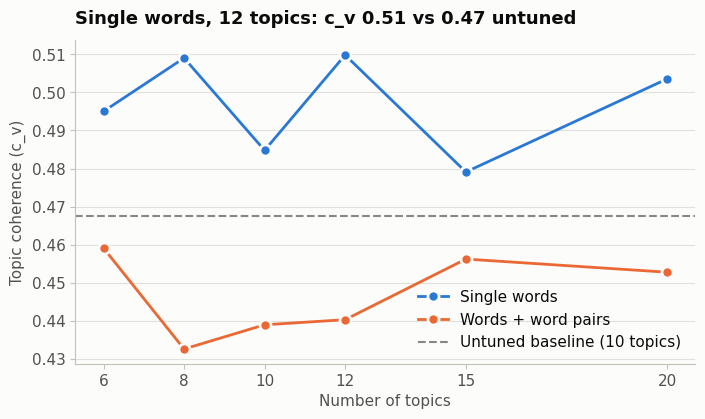

In [35]:
K_GRID = [6, 8, 10, 12, 15, 20]
TEXTS = {"single": tune_single, "pairs": tune_pairs}
LABELS = {"single": "Single words", "pairs": "Words + word pairs"}
tune_issues = df.loc[tune_ids, "issue"].to_numpy()


def issue_nmi(model, dictionary, texts):
    dominant = [max(model.get_document_topics(dictionary.doc2bow(t), minimum_probability=0.0), key=lambda x: x[1])[0]
                for t in texts]
    return normalized_mutual_info_score(tune_issues, dominant)


sweep = []
for kind, texts in TEXTS.items():
    d, c = build_corpus(texts, NO_BELOW, 0.4)
    for k in K_GRID:
        start = time.time()
        sweep.append({"texts": kind, "topics": k, "coherence": coherence(fit_lda(d, c, k), texts, d)})
        print(f"{LABELS[kind]:<18} k={k:>2}: c_v = {sweep[-1]['coherence']:.3f} ({time.time() - start:.0f} s)")
sweep = pd.DataFrame(sweep)
best = sweep.loc[sweep["coherence"].idxmax()]
BEST_K, best_kind = int(best["topics"]), best["texts"]

tuning = []
for no_above in [0.2, 0.4, 0.7]:
    d, c = build_corpus(TEXTS[best_kind], NO_BELOW, no_above)
    model = fit_lda(d, c, BEST_K)
    tuning.append({"setting": f"{LABELS[best_kind]}, {BEST_K} topics, max share {no_above}", "texts": best_kind,
                   "no_above": no_above, "topics": BEST_K, "coherence": coherence(model, TEXTS[best_kind], d),
                   "agreement with CFPB issues (NMI)": issue_nmi(model, d, TEXTS[best_kind])})
d, c = build_corpus(tune_raw, 1, 1.0, None)
untuned = fit_lda(d, c, 10)
tuning.append({"setting": "Untuned: standard stop words only, no filtering, 10 topics", "texts": "raw",
               "no_above": 1.0, "topics": 10, "coherence": coherence(untuned, tune_raw, d),
               "agreement with CFPB issues (NMI)": issue_nmi(untuned, d, tune_raw)})
tuning = pd.DataFrame(tuning)
display(tuning[["setting", "coherence", "agreement with CFPB issues (NMI)"]].style.format(
    {"coherence": "{:.3f}", "agreement with CFPB issues (NMI)": "{:.3f}"}))

UNTUNED_COHERENCE = tuning.loc[tuning["texts"] == "raw", "coherence"].iloc[0]
UNTUNED_NMI = tuning.loc[tuning["texts"] == "raw", "agreement with CFPB issues (NMI)"].iloc[0]
best_setting = tuning[tuning["texts"] != "raw"].sort_values("coherence").iloc[-1]
print(f"Chosen: {best_setting['setting']} (c_v {best_setting['coherence']:.3f}, untuned {UNTUNED_COHERENCE:.3f})")
print("\nTop words of the untuned topics:")
for t in range(10):
    print(f"  {t}: {', '.join(w for w, _ in untuned.show_topic(t, topn=10))}")

fig, ax = plt.subplots(figsize=(8, 4.2))
for color, kind in zip(SERIES, TEXTS):
    part = sweep[sweep["texts"] == kind]
    ax.plot(part["topics"], part["coherence"], color=color, marker="o", markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2, label=LABELS[kind])
ax.axhline(UNTUNED_COHERENCE, color=MUTED, linestyle="--", linewidth=1.5, label="Untuned baseline (10 topics)")
ax.set_xticks(K_GRID)
ax.set_xlabel("Number of topics")
ax.set_ylabel("Topic coherence (c_v)")
ax.legend(loc="best")
ax.set_title(f"{LABELS[best_kind]}, {BEST_K} topics: c_v {best['coherence']:.2f} vs {UNTUNED_COHERENCE:.2f} untuned")
save_fig(fig, "fig07_lda_coherence")

In [36]:
use_pairs = best_setting["texts"] == "pairs"
texts_all = df["lda_tokens"].tolist() if use_pairs else [unigram_tokens(i) for i in range(len(df))]
NO_BELOW_FINAL = max(NO_BELOW, round(20 * SCALE))
final_dictionary, final_corpus = build_corpus([texts_all[i] for i in unique_ids], NO_BELOW_FINAL,
                                              best_setting["no_above"])
start = time.time()
lda = fit_lda(final_dictionary, final_corpus, BEST_K, passes=4 if QUICK_RUN else 8)
LDA_COHERENCE = coherence(lda, [texts_all[i] for i in tune_ids], final_dictionary)
print(f"Final LDA on {len(unique_ids):,} unique complaints in {time.time() - start:.0f} s, c_v = {LDA_COHERENCE:.3f}")

top_words = {t: [w for w, _ in lda.show_topic(t, topn=12)] for t in range(BEST_K)}
NAMING_SYSTEM = ("You name topics found in bank customer complaints. Reply with ONE short name of at most 4 words "
                 "that describes the customer's problem, for example: Overdraft fees. No lists, no line breaks.")
topic_names = {}
for t, words in top_words.items():
    if RUN_OPENAI:
        taken = ", ".join(topic_names.values()) or "none"
        name, _, _ = ask_openai(NAMING_SYSTEM, f"Most important words: {', '.join(words)}\nNames already used: {taken}",
                                max_tokens=12)
        name = name.strip().splitlines()[0].strip().strip('"').strip(".")
        topic_names[t] = " ".join(name.split()[:4])
    else:
        topic_names[t] = " / ".join(words[:3])
print(topic_names)

Final LDA on 43,608 unique complaints in 116 s, c_v = 0.550
{0: 'Fraudulent charges', 1: 'Unauthorized transactions', 2: 'Inaccurate credit reporting', 3: 'Payment processing issues', 4: 'Auto loan repossession', 5: 'Late payment fees', 6: 'Unauthorized fund transfers', 7: 'Deceptive practices notice', 8: 'Deposit hold issues', 9: 'Mortgage servicing issues', 10: 'Transaction dispute resolution', 11: 'Account access issues'}


In [37]:
bows = [final_dictionary.doc2bow(t) for t in texts_all]
theta = np.zeros((len(df), BEST_K), dtype="float32")
for i, bow in enumerate(bows):
    for t, p in lda.get_document_topics(bow, minimum_probability=0.0):
        theta[i, t] = p
df["topic"] = theta.argmax(axis=1)
df["topic_name"] = df["topic"].map(topic_names)

topic_table = pd.DataFrame({
    "topic name": pd.Series(topic_names),
    "top words": pd.Series({t: ", ".join(w[:10]) for t, w in top_words.items()}),
    "share of unique complaints": df.loc[unique_ids, "topic"].value_counts(normalize=True),
    "share of all complaints": df["topic"].value_counts(normalize=True),
}).fillna(0).sort_values("share of all complaints", ascending=False)
display(topic_table.style.format({"share of unique complaints": "{:.1%}", "share of all complaints": "{:.1%}"}))

,topic name,top words,share of unique complaints,share of all complaints
7,Deceptive practices notice,"failure, caused, practices, action, written, including, harm, explanation, act, notice",7.2%,20.7%
3,Payment processing issues,"money, pay, bank, saying, didn, person, work, don, gave, spoke",18.1%,13.2%
5,Late payment fees,"payment, payments, balance, fees, late, fee, credit, paid, pay, charged",11.4%,11.6%
8,Deposit hold issues,"bank, funds, check, deposit, checking, transfer, business, branch, hold, closed",14.0%,10.2%
10,Transaction dispute resolution,"dispute, refund, transaction, claim, merchant, evidence, charge, denied, case, investigation",12.4%,9.0%
6,Unauthorized fund transfers,"transactions, unauthorized, american, express, regulation, electronic, fraud, authorized, fund, investigation",2.1%,8.7%
0,Fraudulent charges,"card, credit, charges, debit, bank, opened, closed, cards, accounts, report",10.8%,8.1%
9,Mortgage servicing issues,"mortgage, loan, escrow, insurance, home, property, servicing, foreclosure, documents, application",6.6%,4.8%
2,Inaccurate credit reporting,"credit, reporting, report, debt, inaccurate, act, reported, fcra, identity, fair",5.2%,4.6%
11,Account access issues,"cash, app, access, support, verification, security, address, identity, verify, locked",5.2%,3.8%


Agreement with the CFPB issue labels (NMI): 0.245, random topics: 0.002


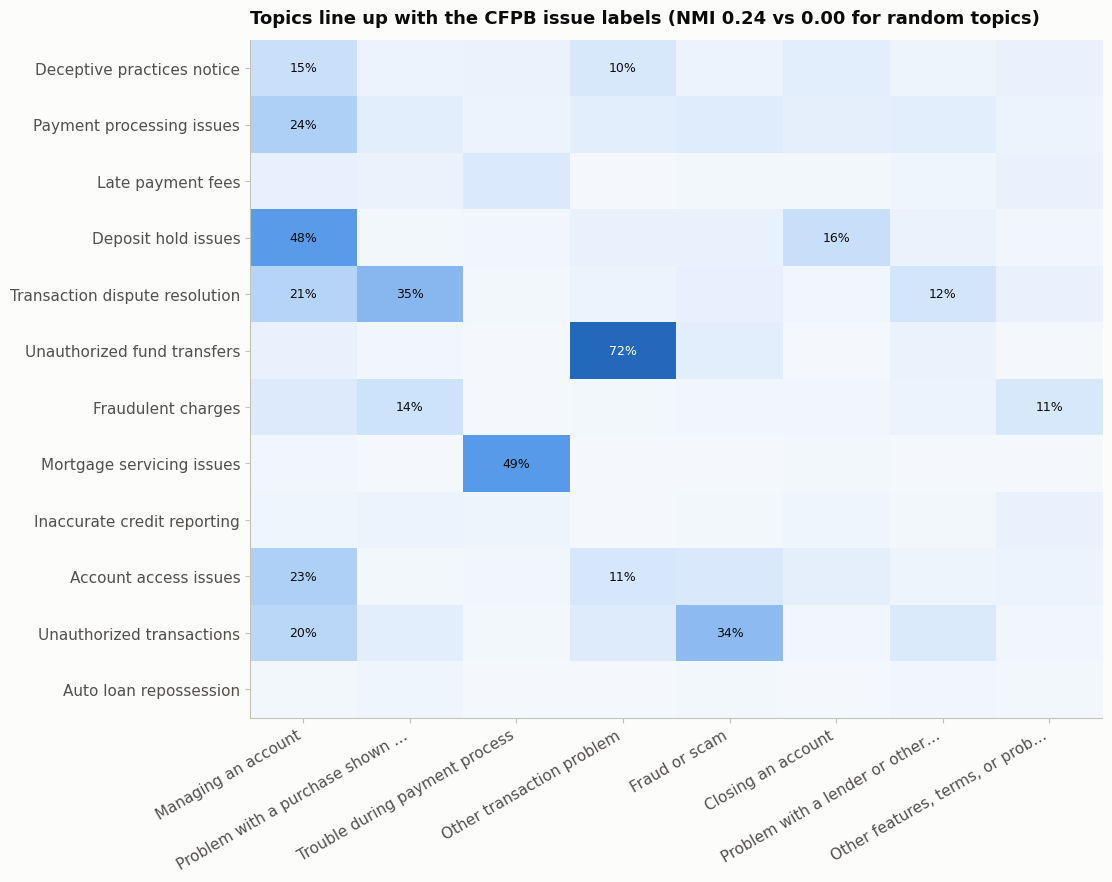

In [38]:
u = df.loc[unique_ids]
NMI = normalized_mutual_info_score(u["issue"], u["topic"])
NMI_RANDOM = normalized_mutual_info_score(u["issue"], np.random.default_rng(SEED).permutation(u["topic"].to_numpy()))
print(f"Agreement with the CFPB issue labels (NMI): {NMI:.3f}, random topics: {NMI_RANDOM:.3f}")

top_issues = u["issue"].value_counts().index[:8]
heat = pd.crosstab(u["topic"], u["issue"], normalize="index").reindex(columns=top_issues, fill_value=0)
heat = heat.reindex(topic_table.index, fill_value=0)
fig, ax = plt.subplots(figsize=(11, 0.55 * BEST_K + 2.2))
ax.imshow(heat.to_numpy(), cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.grid(False)
ax.set_yticks(range(len(heat)), [topic_names[t] for t in heat.index])
ax.set_xticks(range(len(top_issues)), [i if len(i) <= 32 else i[:30] + "…" for i in top_issues], rotation=30, ha="right")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iat[i, j]
        if value >= 0.1:
            ax.text(j, i, f"{value:.0%}", ha="center", va="center", color="white" if value > 0.5 else INK, fontsize=9)
ax.set_title(f"Topics line up with the CFPB issue labels (NMI {NMI:.2f} vs {NMI_RANDOM:.2f} for random topics)")
save_fig(fig, "fig08_topics_vs_cfpb_issues")

In [39]:
topic_weekly = (df[df["week"].isin(WEEKS)].groupby(["week", "topic"]).size()
                  .unstack(fill_value=0).reindex(index=WEEKS, columns=range(BEST_K), fill_value=0))
normal = topic_weekly.median().clip(lower=1)
SPIKE_FACTOR = 3
MIN_ALARM = max(5, round(30 * SCALE))
times_normal = topic_weekly / normal
alarm_mask = (times_normal >= SPIKE_FACTOR) & (topic_weekly >= MIN_ALARM)
alarm_cells = list(zip(*np.where(alarm_mask.to_numpy())))
alarms = pd.DataFrame([{
    "week": WEEKS[w].strftime("%d %b %Y"), "topic": topic_names[t], "complaints": int(topic_weekly.iat[w, t]),
    "normal week": float(normal.iloc[t]), "times normal": float(times_normal.iat[w, t]),
} for w, t in alarm_cells])
print(f"{len(alarms)} alarms (a topic at {SPIKE_FACTOR}× its normal weekly volume or more)")
if len(alarms):
    display(alarms.style.format({"complaints": "{:,}", "normal week": "{:.0f}", "times normal": "{:.1f}×"}))

EVENTS = pd.DataFrame([
    ("2025-01-14", "CFPB sues Capital One over 360 Savings interest rates"),
    ("2025-01-16", "CFPB orders Block (Cash App) to pay up to USD 175 million over fraud handling"),
    ("2025-01-16", "Outage at vendor FIS delays Capital One deposits until 19 January"),
], columns=["date", "event"])
EVENTS["date"] = pd.to_datetime(EVENTS["date"])
alarm_weeks = sorted({WEEKS[w] for w, _ in alarm_cells})


def first_alarm_after(event_date, days=7):
    hits = [w for w in alarm_weeks if w + pd.Timedelta(days=6) >= event_date and w <= event_date + pd.Timedelta(days=days)]
    return hits[0] if hits else None


EVENTS["alarm week"] = [first_alarm_after(d) for d in EVENTS["date"]]
EVENTS["alarm within 7 days"] = EVENTS["alarm week"].notna()
EVENTS["alarm week"] = EVENTS["alarm week"].map(lambda w: w.strftime("%d %b %Y") if w is not None else "none")
display(EVENTS.assign(date=EVENTS["date"].dt.strftime("%d %b %Y")))
ALARM_OK = bool(EVENTS["alarm within 7 days"].all())

19 alarms (a topic at 3× its normal weekly volume or more)


,week,topic,complaints,normal week,times normal
0,13 Jan 2025,Unauthorized transactions,125,29,4.3×
1,13 Jan 2025,Payment processing issues,885,130,6.8×
2,13 Jan 2025,Late payment fees,"1,387",96,14.4×
3,13 Jan 2025,Unauthorized fund transfers,"3,652",4,913.0×
4,13 Jan 2025,Deceptive practices notice,"6,384",72,88.7×
5,13 Jan 2025,Deposit hold issues,538,111,4.8×
6,13 Jan 2025,Account access issues,154,39,3.9×
7,20 Jan 2025,Late payment fees,638,96,6.6×
8,20 Jan 2025,Unauthorized fund transfers,650,4,162.5×
9,20 Jan 2025,Deceptive practices notice,"1,880",72,26.1×


,date,event,alarm week,alarm within 7 days
0,14 Jan 2025,CFPB sues Capital One over 360 Savings interest rates,13 Jan 2025,True
1,16 Jan 2025,CFPB orders Block (Cash App) to pay up to USD 175 million over fraud handling,13 Jan 2025,True
2,16 Jan 2025,Outage at vendor FIS delays Capital One deposits until 19 January,13 Jan 2025,True


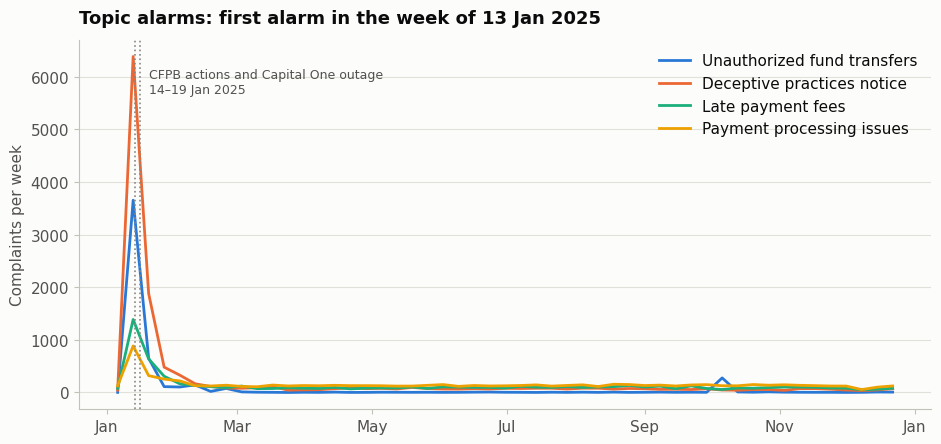

In [40]:
spiking = times_normal.max().sort_values(ascending=False).index[:4]
fig, ax = plt.subplots(figsize=(11, 4.8))
for color, t in zip(SERIES, spiking):
    ax.plot(topic_weekly.index, topic_weekly[t], color=color, label=topic_names[t])
for date in EVENTS["date"].unique():
    ax.axvline(date, color=MUTED, linestyle=":", linewidth=1.2)
ax.annotate("CFPB actions and Capital One outage\n14–19 Jan 2025", (EVENTS["date"].min(), ax.get_ylim()[1] * 0.92),
            xytext=(10, 0), textcoords="offset points", color=INK_2, fontsize=9, va="top")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("Complaints per week")
first_alarm = alarm_weeks[0].strftime("%d %b %Y") if alarm_weeks else "none"
ax.set_title(f"Topic alarms: first alarm in the week of {first_alarm}")
ax.legend(loc="upper right")
save_fig(fig, "fig09_topic_trends_and_alarms")

## 8. Assist: RAG case-brief assistant (main method 3)

**What it does.** When a new complaint arrives, the assistant:

1. Finds the 5 most similar past complaints with **hybrid search**: FAISS on the sentence embeddings from section 4 (meaning) and BM25 (exact words), combined by reciprocal rank fusion. Assignment 3 used the same FAISS + BM25 pair.
2. Asks **Qwen3-4B** (the same Hugging Face model as Assignment 3) to write a four-line case brief using only the new complaint and those past cases, citing them as [1] to [5].
3. Shows the brief with the team from the Word2Vec router (section 5) and the payout risk (section 6).

**Design choices.**

- The knowledge base is the training split only. The test complaints play the role of new arrivals, so the assistant never retrieves the complaint it is answering.
- We also test Assignment 3's metadata filter, searching only the routed team's past complaints. It looks attractive, but when the router is wrong, the filter hides every relevant case, so the table below measures whether it helps.
- The CFPB data has no text of the bank's actual reply, so the brief reports how similar cases were *closed*, which is a real outcome, and never invents what was said to the customer.

**Evaluation.**

- **Retrieval:** precision@5, the share of the 5 retrieved past cases that have the same CFPB issue as the new complaint. It is compared with keyword search alone (BM25), FAISS alone, FAISS with the team filter, and random past cases from the routed team.
- **Briefs:** 20 test complaints, 4 per product. RAGAs faithfulness and answer relevancy are scored with `gpt-4o-mini` as the judge (Session 11, Assignment 3). An LLM judge also scores usefulness from 1 to 5, and we spot-check the judge against our own scores.

In [41]:
kb_ids = train_idx
kb_index = faiss.IndexFlatIP(emb.shape[1])
kb_index.add(emb[kb_ids])
kb_product = df.loc[kb_ids, "product"].to_numpy()
ALLOWED = {p: np.where(kb_product == p)[0].astype("int64") for p in PRODUCTS}


def dense_search(row, product=None, k=5):
    query = emb[row:row + 1]
    if product is None:
        _, ids = kb_index.search(query, k)
    else:
        allowed = ALLOWED[product]
        selector = faiss.IDSelectorBatch(len(allowed), faiss.swig_ptr(allowed))
        _, ids = kb_index.search(query, k, params=faiss.SearchParameters(sel=selector))
    return [int(kb_ids[i]) for i in ids[0] if i != -1]


start = time.time()
bm25 = BM25Okapi([df.at[i, "tokens"] for i in kb_ids])
print(f"Knowledge base: {len(kb_ids):,} past complaints, BM25 index built in {time.time() - start:.0f} s")


bm25_cache = {}


def bm25_search(row, k=5, depth=50):
    if row not in bm25_cache:
        scores = bm25.get_scores(list(dict.fromkeys(df.at[row, "tokens"]))[:60])
        bm25_cache[row] = [int(kb_ids[i]) for i in np.argsort(-scores)[:depth]]
    return bm25_cache[row][:k]


def hybrid_search(row, k=5, depth=50, c=60):
    fused = {}
    for ranking in (dense_search(row, k=depth), bm25_search(row, k=depth)):
        for rank, hit in enumerate(ranking):
            fused[hit] = fused.get(hit, 0.0) + 1.0 / (c + rank + 1)
    return sorted(fused, key=fused.get, reverse=True)[:k]


def random_search(row, product, k=5):
    return [int(kb_ids[i]) for i in rng.choice(ALLOWED[product], k, replace=False)]

Knowledge base: 34,886 past complaints, BM25 index built in 1 s


,precision@5 (same issue),precision@5 (same product),ms per query
method,,,
Random past cases (routed team),0.201,0.800,0.1
Keyword search (BM25),0.355,0.691,408.9
FAISS (meaning),0.390,0.767,6.2
FAISS + routed-team filter,0.403,0.800,5.2
Hybrid FAISS + BM25 (our pipeline),0.393,0.743,6.5


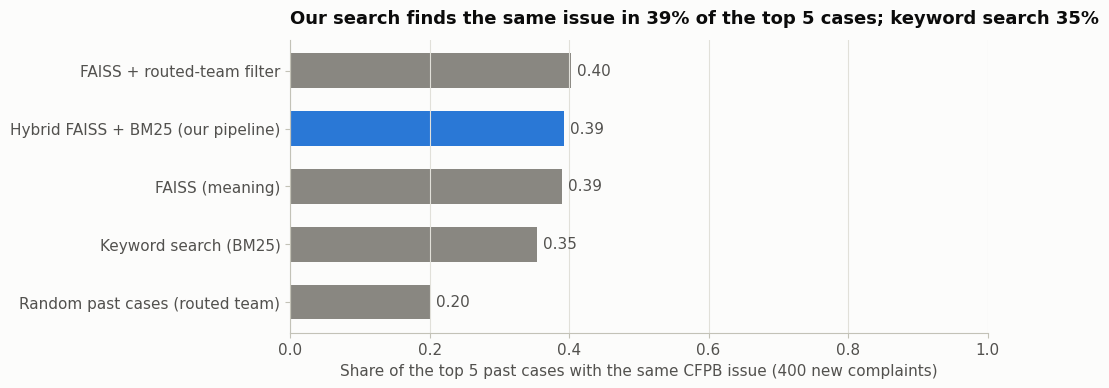

In [42]:
EVAL_N = 100 if QUICK_RUN else 400
eval_rows = pd.Series(test_idx).sample(EVAL_N, random_state=SEED).to_numpy()
rng = np.random.default_rng(SEED)
search_methods = {
    "Random past cases (routed team)": lambda r: random_search(r, route_pred[r]),
    "Keyword search (BM25)": lambda r: bm25_search(r),
    "FAISS (meaning)": lambda r: dense_search(r),
    "FAISS + routed-team filter": lambda r: dense_search(r, route_pred[r]),
    "Hybrid FAISS + BM25 (our pipeline)": lambda r: hybrid_search(r),
}


def share_same(row, hits, field):
    return np.mean([df.at[h, field] == df.at[row, field] for h in hits]) if hits else 0.0


retrieval_rows = []
for name, search in search_methods.items():
    start = time.time()
    results = [(r, search(r)) for r in eval_rows]
    retrieval_rows.append({"method": name,
                           "precision@5 (same issue)": np.mean([share_same(r, h, "issue") for r, h in results]),
                           "precision@5 (same product)": np.mean([share_same(r, h, "product") for r, h in results]),
                           "ms per query": (time.time() - start) / EVAL_N * 1000})
retrieval = pd.DataFrame(retrieval_rows).set_index("method")
display(retrieval.style.format({"precision@5 (same issue)": "{:.3f}", "precision@5 (same product)": "{:.3f}",
                                "ms per query": "{:.1f}"}))
P5_OURS = retrieval.loc["Hybrid FAISS + BM25 (our pipeline)", "precision@5 (same issue)"]
P5_BM25 = retrieval.loc["Keyword search (BM25)", "precision@5 (same issue)"]

values = retrieval["precision@5 (same issue)"].sort_values()
colors = [SERIES[0] if "our pipeline" in name else MUTED for name in values.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(values.index, values.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in values.values], padding=4, color=INK_2)
ax.set_xlim(0, 1)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"Share of the top 5 past cases with the same CFPB issue ({EVAL_N} new complaints)")
ax.set_title(f"Our search finds the same issue in {P5_OURS:.0%} of the top 5 cases; keyword search {P5_BM25:.0%}")
save_fig(fig, "fig10_retrieval_precision")

In [43]:
LLM_MODEL = "Qwen/Qwen3-4B"

if RUN_QWEN:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL)
    llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype=torch.float16).to(DEVICE)


def generate(messages, max_new_tokens=350):
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    text = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()


BRIEF_SYSTEM = """You help a bank's complaints team. Use ONLY the new complaint and the numbered past cases.
Write a case brief with exactly these four lines and nothing else:
Summary: what the customer says happened and what they want, in one or two sentences.
Main issue: the main problem in a few words.
Similar cases: in one or two sentences, how the most relevant past cases were closed (for example "closed with
explanation" or "closed with monetary relief"), citing them like [1] or [3].
Next step: one concrete action for the agent.
Do not add any fact that is not in the new complaint or the past cases."""


def case_parts(row, hits):
    parts = ["NEW COMPLAINT:\n" + " ".join(df.at[row, "text"].split()[:300])]
    for n, h in enumerate(hits, start=1):
        parts.append(f"[{n}] Past case | {SHORT[df.at[h, 'product']]} | {df.at[h, 'issue']} | "
                     f"closed: {df.at[h, 'company_response']}\n" + " ".join(df.at[h, "text"].split()[:120]))
    return parts


risk_by_row = dict(zip(test_idx, payout_scores["Word2Vec text + product"]))
risk_cut = np.quantile(payout_scores["Word2Vec text + product"], [0.5, 0.8])


def risk_label(row):
    score = risk_by_row[row]
    return "high" if score >= risk_cut[1] else ("medium" if score >= risk_cut[0] else "low")


golden_rows = df.loc[test_idx].groupby("product").sample(4, random_state=SEED).index.to_numpy()
briefs = []
if RUN_QWEN:
    for row in golden_rows:
        hits = hybrid_search(row)
        parts = case_parts(row, hits)
        start = time.time()
        brief = generate([{"role": "system", "content": BRIEF_SYSTEM}, {"role": "user", "content": "\n\n".join(parts)}])
        briefs.append({"row": row, "hits": hits, "parts": parts, "brief": brief, "seconds": time.time() - start})
    print(f"{len(briefs)} case briefs, {np.mean([b['seconds'] for b in briefs]):.1f} s each on average")
else:
    print("Case briefs skipped: Qwen3-4B needs a GPU runtime (RUN_QWEN = False)")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

20 case briefs, 7.3 s each on average


In [44]:
for b in briefs[:2]:
    row = b["row"]
    card = (f"**Complaint {df.at[row, 'complaint_id']}** ({df.at[row, 'date_received']:%d %b %Y}, {df.at[row, 'company']})\n\n"
            f"> {' '.join(df.at[row, 'text'].split()[:90])} ...\n\n"
            f"**Routed to:** {SHORT[route_pred[row]]} (consumer chose: {SHORT[df.at[row, 'product']]}) · "
            f"**Payout risk:** {risk_label(row)} · "
            f"**Similar past cases:** {', '.join(df.loc[b['hits'], 'complaint_id'])}\n\n"
            + b["brief"].replace("\n", "\n\n"))
    display(Markdown(card.replace("$", "USD ")))

**Complaint 11923834** (04 Feb 2025, Block, Inc.)

> Unauthorized transactions were done on my CashAPP account and it was stated that CashAPP was unable to provide any additional support regarding the claim and no further action will be taken. I did not authorize anyone to have access to my account. Dates/Times and Amounts : ...

**Routed to:** Money transfer (consumer chose: Checking/savings) · **Payout risk:** low · **Similar past cases:** 14386275, 11721471, 11768110, 11627521, 13064709

Summary: The customer claims unauthorized transactions were made on their CashAPP account and seeks resolution as CashAPP refused to provide further support.  

Main issue: Unauthorized transactions on CashAPP account.  

Similar cases: Closed with explanation [1], [2], [3], [5].  

Next step: Contact CashAPP support to escalate the complaint and request further investigation into the unauthorized transactions.

**Complaint 13777939** (30 May 2025, WELLS FARGO & COMPANY)

> was offering a promotion that if you opened a Checking account and met the requirements by a particular date, they were offering bonus cash. account was USD 120.00 Another was USD  And other was USD  I applied and was approved and open all 3 checking accounts the same day or with 24 hours of the first one. I met all the requirements and the deadline date, and only received one cash bonus of USD 120.00 And the representative said because I was already an existing customer I dont quality for the others. ...

**Routed to:** Checking/savings (consumer chose: Checking/savings) · **Payout risk:** medium · **Similar past cases:** 13688449, 15854084, 17894008, 17249836, 15046652

Summary: The customer opened three checking accounts and met the requirements for bonus cash but only received one bonus, claiming they should have received all three.  

Main issue: Ineligible for multiple bonuses due to existing customer status.  

Similar cases: Closed with explanation [1], closed with explanation [3], closed with explanation [5].  

Next step: Verify if the customer was eligible for all three bonuses based on the specific terms of each promotion and the timing of account openings.

In [45]:
FAITHFULNESS = RELEVANCY = None
if briefs and RUN_OPENAI:
    from ragas import evaluate, EvaluationDataset, RunConfig
    from ragas.metrics import faithfulness, answer_relevancy
    from ragas.llms import LangchainLLMWrapper
    from ragas.embeddings import LangchainEmbeddingsWrapper
    from langchain_core.embeddings import Embeddings
    from langchain_openai import ChatOpenAI

    judge = LangchainLLMWrapper(ChatOpenAI(model=JUDGE_MODEL, temperature=0))

    class MpnetEmbeddings(Embeddings):
        def embed_documents(self, texts):
            return embedder.encode(texts, normalize_embeddings=True).tolist()

        def embed_query(self, text):
            return embedder.encode(text, normalize_embeddings=True).tolist()

    eval_dataset = EvaluationDataset.from_list([
        {"user_input": "Write a case brief for this complaint: " + " ".join(df.at[b["row"], "text"].split()[:150]),
         "response": b["brief"], "retrieved_contexts": b["parts"]}
        for b in briefs])
    ragas_scores = evaluate(eval_dataset, metrics=[faithfulness, answer_relevancy], llm=judge,
                            embeddings=LangchainEmbeddingsWrapper(MpnetEmbeddings()),
                            run_config=RunConfig(max_workers=2, timeout=600, max_retries=5, max_wait=60))
    ragas_table = ragas_scores.to_pandas()
    ragas_table.insert(0, "complaint_id", [df.at[b["row"], "complaint_id"] for b in briefs])
    ragas_table.insert(1, "product", [SHORT[df.at[b["row"], "product"]] for b in briefs])
    FAITHFULNESS = ragas_table["faithfulness"].mean()
    RELEVANCY = ragas_table["answer_relevancy"].mean()
    print(f"RAGAs over {len(briefs)} briefs: faithfulness {FAITHFULNESS:.2f}, answer relevancy {RELEVANCY:.2f}")
    display(ragas_table[["complaint_id", "product", "faithfulness", "answer_relevancy"]]
            .style.format({"faithfulness": "{:.2f}", "answer_relevancy": "{:.2f}"}))
else:
    print("RAGAs skipped (needs the case briefs and RUN_OPENAI = True)")

Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]

RAGAs over 20 briefs: faithfulness 0.75, answer relevancy 0.58


,complaint_id,product,faithfulness,answer_relevancy
0,11923834,Checking/savings,0.67,0.60
1,13777939,Checking/savings,0.67,0.57
2,16802455,Checking/savings,1.00,0.55
3,18149666,Checking/savings,1.00,0.52
4,12267031,Credit card,0.71,0.63
5,13530049,Credit card,0.75,0.57
6,14543117,Credit card,0.83,0.62
7,14391591,Credit card,0.62,0.61
8,14182644,Money transfer,0.86,0.50
9,11668164,Money transfer,0.75,0.65


### Why faithfulness is below target

Faithfulness asks: is every statement in the brief backed by the complaint or the past cases? The "Next step" line is advice for the agent, not a fact, so it can never be found in the material. Our guess is that this line pulls the score down. To test it, we score the same 20 briefs again without that line. The target in the scorecard stays on the whole brief.

In [46]:
FAITHFULNESS_FACTS = None
if briefs and RUN_OPENAI:
    def factual_lines(brief):
        return "\n".join(line for line in brief.splitlines()
                         if not line.strip().lstrip("*").lower().startswith("next step"))

    facts_dataset = EvaluationDataset.from_list([
        {"user_input": "Write a case brief for this complaint: " + " ".join(df.at[b["row"], "text"].split()[:150]),
         "response": factual_lines(b["brief"]), "retrieved_contexts": b["parts"]}
        for b in briefs])
    facts_scores = evaluate(facts_dataset, metrics=[faithfulness], llm=judge,
                            run_config=RunConfig(max_workers=2, timeout=600, max_retries=5, max_wait=60))
    FAITHFULNESS_FACTS = facts_scores.to_pandas()["faithfulness"].mean()
    print(f"Faithfulness, whole brief: {FAITHFULNESS:.2f} | without the Next step line: {FAITHFULNESS_FACTS:.2f}")

Evaluating:   0%|          | 0/20 [00:00<?, ?it/s]

Faithfulness, whole brief: 0.75 | without the Next step line: 0.94


In [47]:
JUDGE_SYSTEM = """You review case briefs written for a bank's complaints team. Be strict.
You get the material the brief was written from, then the brief.
First list every statement in the brief that is not supported by the material.
Then score usefulness on this scale:
1 = wrong or misleading, 2 = vague or generic, 3 = correct but the agent still has to read the whole complaint,
4 = correct and specific, saves the agent time, 5 = correct, specific and the next step is ready to act on.
Return JSON with these keys:
"unsupported_statements": a list of strings (empty if none),
"usefulness": 1 to 5,
"reason": one short sentence."""

judge_table = None
if briefs and RUN_OPENAI:
    verdicts = []
    for n, b in enumerate(briefs):
        reply, _, _ = ask_openai(JUDGE_SYSTEM, "MATERIAL:\n" + "\n\n".join(b["parts"]) + "\n\nBRIEF:\n" + b["brief"],
                                 max_tokens=400, json_mode=True)
        result = json.loads(reply)
        problems = result.get("unsupported_statements") or []
        verdicts.append({"brief": n, "complaint_id": df.at[b["row"], "complaint_id"],
                         "usefulness": int(result.get("usefulness", 0)),
                         "unsupported statements": len(problems),
                         "example": problems[0] if problems else "",
                         "reason": result.get("reason", "")})
    judge_table = pd.DataFrame(verdicts).set_index("brief")
    print(f"Judge usefulness: {judge_table['usefulness'].mean():.2f} / 5 "
          f"(range {judge_table['usefulness'].min()}–{judge_table['usefulness'].max()}), "
          f"briefs with unsupported statements: {(judge_table['unsupported statements'] > 0).sum()} of {len(judge_table)}")
    display(judge_table)

Judge usefulness: 3.20 / 5 (range 2–5), briefs with unsupported statements: 12 of 20


,complaint_id,usefulness,unsupported statements,example,reason
brief,,,,,
0,11923834,4,0,,The brief accurately summarizes the complaint and provides specific details for the agent to act on.
1,13777939,3,2,Main issue: Ineligible for multiple bonuses due to existing customer status.,The brief contains some correct information but lacks specific details that would help the agent resolve the complaint efficiently.
2,16802455,3,1,"Similar cases: [1] closed with non-monetary relief for rude treatment during account closure, [3] closed with explanation for account closure without proper notice.",The brief contains correct information but lacks specific details that would help the agent understand the complaint fully.
3,18149666,3,2,Chime denied my dispute despite evidence of internal negligence.,The brief contains some correct information but lacks specific details that would help the agent understand the complaint fully.
4,12267031,5,0,,The brief accurately summarizes the complaint and provides a clear next step.
5,13530049,3,1,"Similar cases: Closed with explanation [1], closed with non-monetary relief [2], closed with non-monetary relief [3].",The brief contains unsupported statements and lacks specific details that would help the agent.
6,14543117,2,3,the electric appliances were never delivered and returned,The brief contains vague statements that are not fully supported by the material.
7,14391591,2,2,"The bank only allows auto-pay for the minimum or full balance, which limits their ability to pay off debt faster or avoid interest.",The brief contains unsupported claims and lacks specificity.
8,14182644,4,0,,The brief accurately summarizes the complaint and provides specific next steps.


### Human spot-check of the judge

An LLM judge can be biased (Session 11, *"watch judge bias"*). Read briefs 0 to 4 below and give each your own usefulness score on the same scale as the judge:

1 = wrong or misleading · 2 = vague or generic · 3 = correct, but the agent still has to read the whole complaint · 4 = correct and specific, saves time · 5 = correct, specific and the next step is ready to act on

Type them into `HUMAN_USEFULNESS`, for example `{0: 4, 1: 3, 2: 5, 3: 4, 4: 2}`, and run the cell.

In [48]:
for n, b in enumerate(briefs[:5]):
    print(f"--- Brief {n} | complaint {df.at[b['row'], 'complaint_id']}")
    print(" ".join(df.at[b["row"], "text"].split()[:60]), "...\n")
    print(b["brief"], "\n")

--- Brief 0 | complaint 11923834
Unauthorized transactions were done on my CashAPP account and it was stated that CashAPP was unable to provide any additional support regarding the claim and no further action will be taken. I did not authorize anyone to have access to my account. Dates/Times and Amounts : ...

Summary: The customer claims unauthorized transactions were made on their CashAPP account and seeks resolution as CashAPP refused to provide further support.  
Main issue: Unauthorized transactions on CashAPP account.  
Similar cases: Closed with explanation [1], [2], [3], [5].  
Next step: Contact CashAPP support to escalate the complaint and request further investigation into the unauthorized transactions. 

--- Brief 1 | complaint 13777939
was offering a promotion that if you opened a Checking account and met the requirements by a particular date, they were offering bonus cash. account was $120.00 Another was $ And other was $ I applied and was approved and open all 3 checking

In [49]:
HUMAN_USEFULNESS = {0: 4, 1: 3, 2: 4, 3: 3, 4: 4}
JUDGE_AGREEMENT = None
if HUMAN_USEFULNESS and judge_table is not None:
    compare = pd.DataFrame({"human": pd.Series(HUMAN_USEFULNESS), "judge": judge_table["usefulness"]}).dropna()
    compare["difference"] = compare["judge"] - compare["human"]
    JUDGE_AGREEMENT = (compare["difference"].abs() <= 1).mean()
    display(compare)
    print(f"Judge within 1 point of the human on {JUDGE_AGREEMENT:.0%} of briefs, "
          f"mean difference {compare['difference'].mean():+.2f}")
else:
    print("Human scores not entered yet")

,human,judge,difference
0,4.0,4,0.0
1,3.0,3,0.0
2,4.0,3,-1.0
3,3.0,3,0.0
4,4.0,5,1.0


Judge within 1 point of the human on 100% of briefs, mean difference +0.00


## 9. Responsible AI

| Risk | What we did |
|---|---|
| Privacy | The CFPB removes personal details before publishing (XXXX). The notebook<br>stores no names or account numbers, and the brief prompt forbids new facts. |
| Unfair treatment | The payout model is checked for Older American and Servicemember complaints<br>(section 6) against the 5-point target. |
| Made-up answers | Briefs only use retrieved cases; RAGAs faithfulness and the judge measure<br>unsupported claims; a person reads a sample. |
| Automation without oversight | Every output is a suggestion: an agent confirms the route, reviews<br>the risk and edits the brief. |
| Label quality | Products and issues are chosen by consumers, so some labels are wrong.<br>Scores are a fair estimate, not an exact one. |
| Regulation | Complaint handling is not a high-risk use under the EU AI Act; it would need<br>human oversight and logging, which this design already has. |

## 10. Scorecard: targets against results

In [50]:
def verdict(ok):
    if isinstance(ok, str):
        return ok
    return "not measured yet" if ok is None else ("✅ met" if ok else "❌ not met")


TUNED_NMI = best_setting["agreement with CFPB issues (NMI)"]
scorecard = pd.DataFrame([
    ("Clean", "Copy pairs confirmed by a person", "–", "≥ 18 of 20",
     f"{HUMAN_CONFIRMED} of {len(human_check)}" if HUMAN_CONFIRMED is not None else "–",
     None if HUMAN_CONFIRMED is None else HUMAN_CONFIRMED >= 18),
    ("Route", "Accuracy on held-out complaints", f"Keyword rules {ACC_KW:.0%}", "≥ 80% and above keywords",
     f"{ACC_ROUTER:.0%} (macro-F1 {F1_ROUTER:.2f})", bool(ACC_ROUTER >= 0.8 and ACC_ROUTER > ACC_KW)),
    ("Prioritise", "Payouts caught in the riskiest 20%", "Random 20%", "≥ 40%",
     f"{CAUGHT_20:.0%}", bool(CAUGHT_20 >= 0.4)),
    ("Watch", "Topic coherence (c_v)", f"Untuned {UNTUNED_COHERENCE:.2f}", "≥ 0.40 and above untuned",
     f"{LDA_COHERENCE:.2f}", bool(LDA_COHERENCE >= 0.4 and LDA_COHERENCE > UNTUNED_COHERENCE)),
    ("Watch", "Agreement with CFPB issues (NMI)", f"Untuned {UNTUNED_NMI:.2f}", "no target (diagnostic)",
     f"{TUNED_NMI:.2f}", "ℹ️ diagnostic"),
    ("Watch", "Alarm within 7 days of the January events", "–", "yes",
     "yes" if ALARM_OK else "no", ALARM_OK),
    ("Assist", "Precision@5 (same issue)", f"BM25 {P5_BM25:.2f}", "above BM25",
     f"{P5_OURS:.2f}", bool(P5_OURS > P5_BM25)),
    ("Assist", "RAGAs faithfulness (whole brief)", "–", "≥ 0.80",
     f"{FAITHFULNESS:.2f}" if FAITHFULNESS is not None else "–",
     None if FAITHFULNESS is None else bool(FAITHFULNESS >= 0.8)),
    ("Assist", "RAGAs faithfulness without the Next step line", "–", "no target (diagnostic)",
     f"{FAITHFULNESS_FACTS:.2f}" if FAITHFULNESS_FACTS is not None else "–", "ℹ️ diagnostic"),
    ("Assist", "Judge within 1 point of a person (5 briefs)", "–", "no target (diagnostic)",
     f"{JUDGE_AGREEMENT:.0%}" if JUDGE_AGREEMENT is not None else "–", "ℹ️ diagnostic"),
    ("Fairness", "Shortfall in payouts caught (tagged vs untagged)", "–", "≤ 5 points",
     f"{FAIRNESS_GAP * 100:.1f} points", bool(FAIRNESS_GAP <= 0.05)),
], columns=["stage", "metric", "baseline", "target", "result", "met"])
scorecard["met"] = scorecard["met"].map(verdict)
scorecard.to_csv(os.path.join(FIG_DIR, "scorecard.csv"), index=False)
display(scorecard.set_index("stage"))

,metric,baseline,target,result,met
stage,,,,,
Clean,Copy pairs confirmed by a person,–,≥ 18 of 20,19 of 20,✅ met
Route,Accuracy on held-out complaints,Keyword rules 71%,≥ 80% and above keywords,81% (macro-F1 0.82),✅ met
Prioritise,Payouts caught in the riskiest 20%,Random 20%,≥ 40%,52%,✅ met
Watch,Topic coherence (c_v),Untuned 0.47,≥ 0.40 and above untuned,0.55,✅ met
Watch,Agreement with CFPB issues (NMI),Untuned 0.20,no target (diagnostic),0.23,ℹ️ diagnostic
Watch,Alarm within 7 days of the January events,–,yes,yes,✅ met
Assist,Precision@5 (same issue),BM25 0.35,above BM25,0.39,✅ met
Assist,RAGAs faithfulness (whole brief),–,≥ 0.80,0.75,❌ not met
Assist,RAGAs faithfulness without the Next step line,–,no target (diagnostic),0.94,ℹ️ diagnostic


## 11. Business impact (illustrative)

The value comes from three places: less manual triage, payouts handled earlier, and surges spotted in days instead of weeks. The first one can be sized with the numbers below. **The minutes and the hourly cost are assumptions to confirm with the bank**; the complaint volume and the accuracy come from the data.

In [51]:
COMPLAINTS_PER_YEAR = 11_910
MINUTES_TO_TRIAGE = 10
HOURLY_COST_USD = 45

routed_right = COMPLAINTS_PER_YEAR * ACC_ROUTER
hours_saved = routed_right * MINUTES_TO_TRIAGE / 60
impact = pd.DataFrame([
    ("Complaints with a written story per year (Capital One, 5 products, full 2025 CFPB data)", f"{COMPLAINTS_PER_YEAR:,}", "data"),
    ("Routed correctly without a person reading them first", f"{routed_right:,.0f}", "model result"),
    ("Minutes a person spends reading and routing one complaint", f"{MINUTES_TO_TRIAGE}", "assumption"),
    ("Hours of triage saved per year", f"{hours_saved:,.0f}", "calculated"),
    ("Cost per hour of a complaints analyst (USD)", f"{HOURLY_COST_USD}", "assumption"),
    ("Triage cost saved per year (USD)", f"{hours_saved * HOURLY_COST_USD:,.0f}", "calculated"),
    ("Payouts caught by reviewing the riskiest 20% first", f"{CAUGHT_20:.0%}", "model result"),
    ("Share of complaints that are template copies (bulk answer)", f"{COPY_SHARE:.0%}", "data"),
], columns=["item", "value", "source"])
display(impact.set_index("item"))

,value,source
item,,
"Complaints with a written story per year (Capital One, 5 products, full 2025 CFPB data)","11,910",data
Routed correctly without a person reading them first,"9,639",model result
Minutes a person spends reading and routing one complaint,10,assumption
Hours of triage saved per year,"1,607",calculated
Cost per hour of a complaints analyst (USD),45,assumption
Triage cost saved per year (USD),"72,294",calculated
Payouts caught by reviewing the riskiest 20% first,52%,model result
Share of complaints that are template copies (bulk answer),27%,data


## 12. Findings and conclusions

*To be written from the results of the final Colab run.*

In [52]:
shutil.make_archive("figures", "zip", FIG_DIR)
print("Charts and the scorecard for the slides are in figures.zip:")
print("\n".join(sorted(os.listdir(FIG_DIR))))

Charts and the scorecard for the slides are in figures.zip:
fig01_weekly_complaints_by_product.png
fig02_payout_rate_by_product.png
fig03_unique_vs_template_copies.png
fig04_routing_accuracy.png
fig05_routing_confusion_matrix.png
fig06_payout_gains_curve.png
fig07_lda_coherence.png
fig08_topics_vs_cfpb_issues.png
fig09_topic_trends_and_alarms.png
fig10_retrieval_precision.png
scorecard.csv
